# Toy 1 — Sine Regression: Comparing All 6 Parameter-Generator Families

**The story in one sentence:** on two small, controlled regression problems
with a known (or numerically reliable) reference posterior, a sampler built
from the *exact* posterior score (`SGLDGroup`) matches or beats every other
family here -- including a carefully-tuned *trained* Langevin sampler
(`LangevinGroup`) -- while needing no training loop at all.

**What you'll see, in order:**
1. **Part A** (closed-form PCE posterior) and **Part B** (small NN, numerically
   reliable grid reference) each walk through: train all 6 families on
   identical data -> compare fitted moments and `KL(q||reference)` -> look at
   the posterior's covariance structure directly -> watch the two Langevin
   variants' particles move via trajectory plots -> compare predictive bands.
2. An **Appendix** at the end of each part collects the deeper robustness
   checks and failure-mode diagnoses (gradient explosion through unrolled
   dynamics, KL-estimator sensitivity, a low-rank-vs-full-covariance rank
   sweep) that justify *why* the headline `LangevinGroup` configuration above
   is what it is. Skip it on a first read; it's there for anyone auditing the
   headline numbers.

**Expensive cells are cached** (see the caching cell below): the first
execution after any code change will take as long as before (no way around
training/sampling at least once), but re-running the notebook afterwards --
to tweak a plot's styling or this prose, say -- reuses cached results and
finishes in seconds. Delete `docs/examples/.cache/toy_sine_regression_families/`
(or bump a cache key's version suffix) to force specific results to be
recomputed.

In [1]:
import time

_notebook_start = time.time()

In [2]:
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.distributions as td
import torch.nn.functional as F

from pypolymix.parameter_groups import (
    DeterministicGroup,
    GaussianGroup,
    IIDGaussianGroup,
    LangevinGroup,
    LowRankGaussianGroup,
    SGLDGroup,
    WhitenedGroup,
)
from pypolymix.parameter_groups.kl_estimators import (
    AnalyticKL,
    DiagonalGaussianEntropyKL,
    KNNEntropyKL,
    ReparamMonteCarloKL,
)
from pypolymix.priors import IIDGaussianPrior
from pypolymix.surrogate_models import NeuralNetwork, PolynomialChaosExpansion
from pypolymix import StochasticModel

torch.set_default_dtype(torch.float64)  # precision matters for the closed-form checks below

# Locate _cache_utils.py regardless of whether this notebook is executed with
# cwd == repo root (e.g. `papermill docs/examples/toy_sine...ipynb ...` from
# the repo root) or cwd == its own directory (e.g. mkdocs-jupyter's default).
for _candidate in [pathlib.Path("docs/examples"), pathlib.Path(".")]:
    if (_candidate / "_cache_utils.py").exists():
        sys.path.insert(0, str(_candidate))
        NOTEBOOK_DIR = _candidate
        break
else:
    raise RuntimeError("Could not locate _cache_utils.py -- run from the repo root or docs/examples/.")

from _cache_utils import CacheDir

# Set True to ignore all cached results and recompute everything from scratch.
FORCE_RECOMPUTE = False
CACHE_ROOT = NOTEBOOK_DIR / ".cache" / "toy_sine_regression_families"
cache_a = CacheDir(CACHE_ROOT / "part_a", force=FORCE_RECOMPUTE)
cache_b = CacheDir(CACHE_ROOT / "part_b", force=FORCE_RECOMPUTE)

# "sgld" (exact-score, preconditioned-or-not Langevin dynamics via SGLDGroup --
# see experiments/langevin_diagnosis/FINDINGS.md Experiment 11 and
# experiments/langevin_diagnosis/moe/FINDINGS_moe.md Experiments 11-13) is a
# second Langevin-family entry alongside "langevin" (the original *trained*
# score-network LangevinGroup): SGLDGroup needs no trained network and no
# training loop at all, since the exact posterior score is directly
# computable via autograd through the real surrogate model. Both are kept
# side by side deliberately, not as a replacement, so the notebook shows the
# trained-vs-exact-score contrast rather than erasing the (considerable)
# tuning work behind the "langevin" family.
FAMILIES = ["deterministic", "iid", "full", "lowrank", "langevin", "sgld"]
FAMILY_LABELS = {
    "deterministic": "Deterministic (MAP)",
    "iid": "Mean-field Gaussian",
    "full": "Full-covariance Gaussian",
    "lowrank": "Low-rank Gaussian",
    "langevin": "Langevin (trained)",
    "sgld": "Langevin (exact score)",
}
FAMILY_COLORS = {
    "deterministic": "tab:gray",
    "iid": "tab:blue",
    "full": "tab:green",
    "lowrank": "tab:orange",
    "langevin": "tab:red",
    "sgld": "tab:purple",
}

# Where the exported dat/*.txt tables for the paper's tikz/pgfplots pipeline go.
# pypolymix and the salt paper are separate repos; adjust this path if your
# checkout layout differs.
PAPER_DAT_DIR = pathlib.Path.home() / "projects/salt/doc/paper/stochastic_surrogates/dat"

## Part A — Closed-form validation on a small Polynomial Chaos Expansion

A linear-in-parameters surrogate (PCE) with a Gaussian likelihood and a
Gaussian prior has an exact, closed-form Gaussian posterior -- the ideal
first test case, since every family's `KL(q||true posterior)` is an exact
number, not an approximation of one.

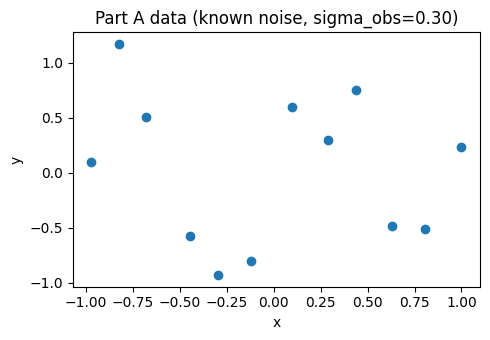

In [3]:
torch.manual_seed(0)

n_train_a = 12
sigma_obs_a = 0.3
sigma_prior_a = 1.0

x_train_a = torch.linspace(-1, 1, n_train_a).unsqueeze(-1) + 0.02 * torch.randn(n_train_a, 1)
x_train_a = x_train_a.clamp(-1, 1)
y_train_a = torch.sin(2 * torch.pi * x_train_a) + 0.3 * torch.sin(6 * torch.pi * x_train_a)
y_train_a = y_train_a + sigma_obs_a * torch.randn(n_train_a, 1)

_, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(x_train_a, y_train_a)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Part A data (known noise, sigma_obs=%.2f)" % sigma_obs_a)
plt.tight_layout()

### Closed-form reference posterior

In [4]:
degree_a = 5
surrogate_a = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=degree_a)
num_terms_a = surrogate_a.num_terms
print(f"PCE has {num_terms_a} coefficients")

with torch.no_grad():
    Phi_a = surrogate_a(x_train_a, torch.eye(num_terms_a)).squeeze(-1).T  # (n_train_a, num_terms_a)

cond_number = torch.linalg.cond(Phi_a.T @ Phi_a).item()
print(f"condition number of Phi^T Phi: {cond_number:.2f} (well-conditioned)")

prior_precision_a = torch.eye(num_terms_a) / sigma_prior_a**2
post_precision_a = Phi_a.T @ Phi_a / sigma_obs_a**2 + prior_precision_a
post_cov_a = torch.linalg.inv(post_precision_a)
post_mean_a = post_cov_a @ (Phi_a.T @ y_train_a.squeeze(-1)) / sigma_obs_a**2
true_posterior_a = td.MultivariateNormal(loc=post_mean_a, covariance_matrix=post_cov_a)

ols_a = torch.linalg.lstsq(Phi_a, y_train_a).solution.squeeze(-1)
print("closed-form posterior mean:", post_mean_a.numpy())
print("ordinary least squares    :", ols_a.numpy())
print("posterior std per coefficient:", torch.diagonal(post_cov_a).sqrt().numpy())

PCE has 6 coefficients
condition number of Phi^T Phi: 9.54 (well-conditioned)


closed-form posterior mean: [-0.02577018 -0.27962172  0.21600675 -0.82008994 -0.18912748  1.39568072]
ordinary least squares    : [-0.0281563  -0.29226031  0.21704277 -0.87808094 -0.20660979  1.49108947]
posterior std per coefficient: [0.08841527 0.14652538 0.18120388 0.20494824 0.21859577 0.23027741]


### Train all 6 families on the identical data/surrogate

Factory functions only (cheap) -- the actual training/sampling happens in the
cached loop below.

In [5]:
def make_group_a(kind):
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    if kind == "deterministic":
        return DeterministicGroup("c", num_terms_a)
    if kind == "iid":
        return IIDGaussianGroup("c", num_terms_a, prior=prior)
    if kind == "full":
        return GaussianGroup("c", num_terms_a, prior=prior)
    if kind == "lowrank":
        return LowRankGaussianGroup("c", num_terms_a, rank=min(3, num_terms_a - 1), prior=prior)
    if kind == "langevin":
        score_model = NeuralNetwork(num_inputs=num_terms_a, num_outputs=num_terms_a, width=16, depth=2)
        return LangevinGroup(
            "c", num_terms_a, score_model=score_model, prior=prior,
            num_particles=64, num_diffusion_steps=300, step_size=2e-3, init_std=1.0,
            kl_estimator=KNNEntropyKL(k=4),
        )
    if kind == "sgld":
        # Exact score, no trained network: log_likelihood_fn is autograd-differentiable
        # through the real surrogate_a forward pass directly, so SGLDGroup needs no
        # separate score/energy model and no training loop (see sgld.py's docstring).
        # preconditioned=False because Part A's posterior is already a simple,
        # well-conditioned quadratic (PCE is linear-in-parameters) -- preconditioning
        # is for ill-conditioned targets (e.g. raw NN weight spaces, see the MoE
        # notebook) and only adds adaptation noise here. step_size/num_diffusion_steps
        # match experiments/langevin_diagnosis/FINDINGS.md Experiment 11's validated
        # configuration (KL=0.0037 nats, matching the full-covariance floor).
        def log_likelihood_fn(theta):
            pred = surrogate_a(x_train_a, theta)
            target = y_train_a.unsqueeze(0).expand_as(pred)
            return -0.5 / sigma_obs_a**2 * (pred - target).pow(2).sum(dim=(1, 2))

        return SGLDGroup(
            "c", num_terms_a, log_likelihood_fn=log_likelihood_fn, prior=prior,
            num_particles=4000, num_diffusion_steps=600, step_size=1e-3, init_std=1.0,
            preconditioned=False,
        )
    raise ValueError(kind)


# LANGEVIN_CLIP_GRAD_NORM: gradient-norm clipping applied only to LangevinGroup's
# training (Appendix A2c/A2d found backprop-through-the-unrolled-chain can
# explode gradients on `surrogate_params`, the same "exploding gradients through
# long unrolled dynamics" failure mode as training long RNNs -- Pascanu, Mikolov
# & Bengio, "On the difficulty of training recurrent neural networks," ICML 2013).
# Left at None (no clipping) for the other four families, whose gradients are not
# backpropagated through an unrolled sampler and were never observed to explode.
# SGLDGroup needs neither a clip nor an optimizer: it has zero nn.Parameters of its
# own (see sgld.py's docstring) -- there is nothing for Adam to update. It is
# sampled once via exact-score ULA, not trained; see train_a's "sgld" branch below.
LANGEVIN_CLIP_GRAD_NORM = 10.0


def train_a(kind, num_epochs=2000, num_samples=32, lr=1e-2, seed=1):
    torch.manual_seed(seed)
    group = make_group_a(kind)
    model = StochasticModel(surrogate_a, group)

    if kind == "sgld":
        # No trained parameters, no optimizer, no epochs: a single exact-score
        # ULA sampling run IS the "training" here -- see
        # experiments/langevin_diagnosis/FINDINGS.md Experiment 11.
        params = model.sample_parameters(num_samples=num_samples)
        pred = surrogate_a(x_train_a, params)
        target = y_train_a.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()  # always 0 for SGLDGroup -- nothing is variationally fit
        history = {"data": [nll_sum.item()], "kl": [kl.item()], "total": [nll_sum.item() + kl.item()]}
        return group, model, history

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    history = {"data": [], "kl": [], "total": []}
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = surrogate_a(x_train_a, params)
        target = y_train_a.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()
        loss = nll_sum + kl
        loss.backward()
        if kind == "langevin":
            torch.nn.utils.clip_grad_norm_(model.parameters(), LANGEVIN_CLIP_GRAD_NORM)
        optimizer.step()
        scheduler.step()
        history["data"].append(nll_sum.item())
        history["kl"].append(kl.item())
        history["total"].append(loss.item())
    return group, model, history

### Cached training/sampling loop

For `deterministic`/`iid`/`full`/`lowrank`/`langevin`, we cache the fitted
`group.state_dict()` (plain tensors, safe to pickle) plus the training
history, and reconstruct a fresh `group`/`model` via `make_group_a` +
`load_state_dict()` on a cache hit -- skipping only the (potentially very
long, for `langevin`) Adam training loop. For `sgld`, there is nothing to
train, but every call to `sample_parameters()` reruns its entire diffusion
chain -- so instead we draw **one** canonical 4000-particle sample here and
cache *that tensor directly*, then reuse it for every downstream computation
(moments, `KL`, the covariance-ellipse plot, and the predictive band) rather
than redrawing. The same canonical-draw idea is applied to `langevin` too
(cheap to redraw post-training, but caching it makes every re-run of this
notebook numerically identical, not just "close", once cached).

In [6]:
EVAL_PARTICLES_A = 4000  # size of the one canonical post-fit draw for langevin/sgld


def _train_a_cached(kind):
    def _compute():
        num_samples = {"langevin": 2048, "sgld": EVAL_PARTICLES_A}.get(kind, 32)
        t0 = time.time()
        group, model, history = train_a(kind, num_samples=num_samples)
        elapsed = time.time() - t0
        payload = {"history": history, "time": elapsed}
        if kind == "sgld":
            payload["particles"] = model.sample_parameters(EVAL_PARTICLES_A).detach()
        else:
            payload["state_dict"] = group.state_dict()
            if kind == "langevin":
                torch.manual_seed(99)  # fixed eval seed, independent of the training seed
                payload["particles"] = group.sample_parameters(EVAL_PARTICLES_A).detach()
        return payload

    payload = cache_a.get(f"parta_{kind}_v1", _compute)
    group = make_group_a(kind)
    model = StochasticModel(surrogate_a, group)
    if "state_dict" in payload:
        group.load_state_dict(payload["state_dict"])
    return {
        "group": group,
        "model": model,
        "history": payload["history"],
        "time": payload["time"],
        "particles": payload.get("particles"),  # None for the 4 trained Gaussian families
    }


results_a = {}
for kind in FAMILIES:
    results_a[kind] = _train_a_cached(kind)
    print(
        f"{FAMILY_LABELS[kind]:28s} trained in {results_a[kind]['time']:.1f}s, "
        f"final loss={results_a[kind]['history']['total'][-1]:.4f}"
    )

[cache hit]  parta_deterministic_v1  <-  parta_deterministic_v1.pt
Deterministic (MAP)          trained in 3.1s, final loss=10.3626
[cache hit]  parta_iid_v1  <-  parta_iid_v1.pt
Mean-field Gaussian          trained in 3.2s, final loss=15.5701
[cache hit]  parta_full_v1  <-  parta_full_v1.pt
Full-covariance Gaussian     trained in 17.9s, final loss=16.2025
[cache hit]  parta_lowrank_v1  <-  parta_lowrank_v1.pt
Low-rank Gaussian            trained in 28.0s, final loss=16.3378


[cache miss] parta_langevin_v1  ->  parta_langevin_v1.pt  (computed in 4118.0s)
Langevin (trained)           trained in 4116.5s, final loss=15.7479


[cache miss] parta_sgld_v1  ->  parta_sgld_v1.pt  (computed in 4.1s)
Langevin (exact score)       trained in 2.3s, final loss=6.4555


### Training dynamics

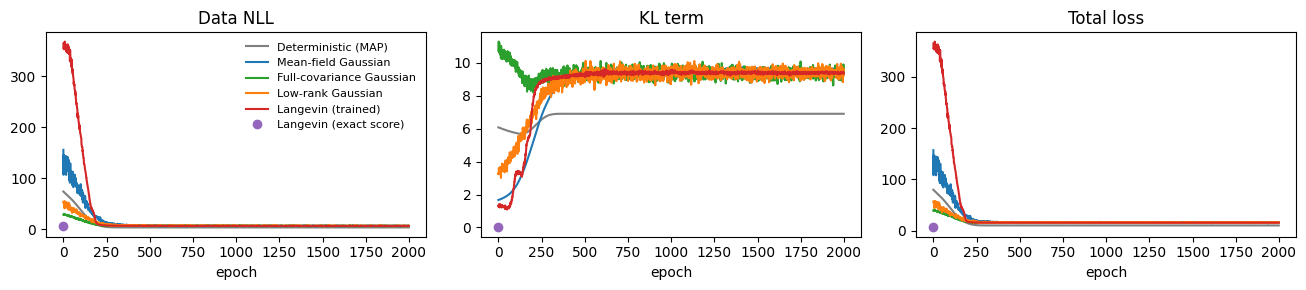

In [7]:
loss_plot_labels = dict(FAMILY_LABELS)
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3))
for ax, metric, title in zip(axes, ["data", "kl", "total"], ["Data NLL", "KL term", "Total loss"]):
    for kind in FAMILIES:
        style = "o" if kind == "sgld" else "-"
        ax.plot(results_a[kind]["history"][metric], style, color=FAMILY_COLORS[kind], label=loss_plot_labels[kind])
    ax.set_title(title)
    ax.set_xlabel("epoch")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

### Validation A1 — posterior mean/std vs the closed-form reference

Predictions with error bars, the most direct check: each family's fitted
per-coefficient mean +/- std, overlaid on the exact closed-form value.

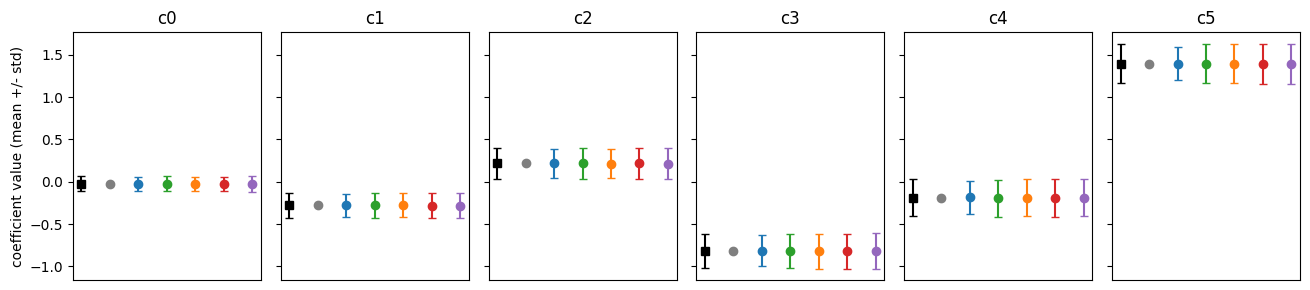

In [8]:
def fitted_moments_a(kind):
    group = results_a[kind]["group"]
    if kind == "deterministic":
        return group.params.detach().clone(), None
    if kind in ("langevin", "sgld"):
        particles = results_a[kind]["particles"]  # cached canonical draw -- no resampling
        mean = particles.mean(0)
        cov = torch.cov(particles.T) + 1e-6 * torch.eye(num_terms_a)
        return mean, cov
    q = group.variational_distribution()
    mean = q.mean.detach()
    if kind == "iid":
        cov = torch.diag(q.variance.detach())
    else:
        cov = q.covariance_matrix.detach()
    return mean, cov


fig, axes = plt.subplots(1, num_terms_a, figsize=(2.2 * num_terms_a, 3), sharey=True)
coeff_idx = np.arange(num_terms_a)
for j, ax in enumerate(axes):
    ax.errorbar(
        [0], [post_mean_a[j].item()], yerr=[post_cov_a[j, j].sqrt().item()],
        fmt="ks", label="closed form", capsize=3,
    )
    for k, kind in enumerate(FAMILIES):
        mean, cov = fitted_moments_a(kind)
        yerr = [cov[j, j].sqrt().item()] if cov is not None else [0.0]
        ax.errorbar(
            [k + 1], [mean[j].item()], yerr=yerr, fmt="o", color=FAMILY_COLORS[kind], capsize=3,
        )
    ax.set_title(f"c{j}")
    ax.set_xticks([])
axes[0].set_ylabel("coefficient value (mean +/- std)")
plt.tight_layout()

In [9]:
# "deterministic" is excluded: a point mass has no covariance, so KL against a
# continuous reference isn't defined in the usual dense-Gaussian sense here.
kl_to_reference_a = {}
for kind in ["iid", "full", "lowrank", "langevin", "sgld"]:
    mean, cov = fitted_moments_a(kind)
    q_full = td.MultivariateNormal(loc=mean, covariance_matrix=cov)
    kl_to_reference_a[kind] = td.kl_divergence(q_full, true_posterior_a).item()

print("KL(q || closed-form true posterior), lower is better:")
for kind, kl in kl_to_reference_a.items():
    flag = "  (moment-matched approximation, not exact q)" if kind in ("langevin", "sgld") else ""
    print(f"  {FAMILY_LABELS[kind]:28s} {kl:8.4f} nats{flag}")

KL(q || closed-form true posterior), lower is better:
  Mean-field Gaussian            0.3055 nats
  Full-covariance Gaussian       0.0033 nats
  Low-rank Gaussian              0.0281 nats
  Langevin (trained)             0.0077 nats  (moment-matched approximation, not exact q)
  Langevin (exact score)         0.0045 nats  (moment-matched approximation, not exact q)


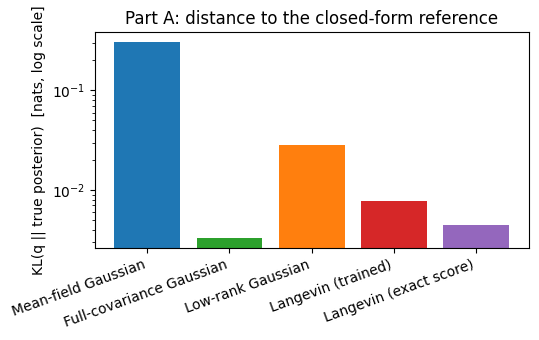

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
kinds_a = ["iid", "full", "lowrank", "langevin", "sgld"]
ax.bar(
    [FAMILY_LABELS[k] for k in kinds_a],
    [kl_to_reference_a[k] for k in kinds_a],
    color=[FAMILY_COLORS[k] for k in kinds_a],
)
ax.set_yscale("log")
ax.set_ylabel("KL(q || true posterior)  [nats, log scale]")
ax.set_title("Part A: distance to the closed-form reference")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()

### Covariance structure: closed-form contour vs. each family's fitted ellipse

The errorbar plot above shows each coefficient's *marginal* spread; it can't
show whether a family also gets the *correlations* between coefficients
right. Picking the two most-correlated coordinate pairs (by the closed-form
posterior's own correlation matrix) and plotting 2-sigma covariance ellipses
makes that visible directly.

Most-correlated coefficient pairs (by |correlation| under the closed-form posterior): [(3, 5), (2, 4)]


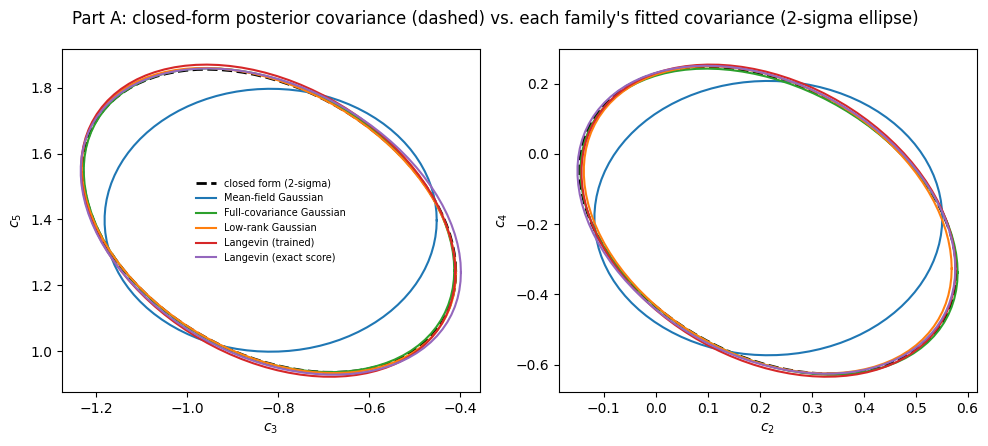

In [11]:
def _top_correlated_pairs(cov, num_pairs=2):
    corr = cov / cov.diagonal().sqrt().outer(cov.diagonal().sqrt())
    abs_corr = corr.abs().clone().fill_diagonal_(0)
    order = torch.argsort(abs_corr.flatten(), descending=True)
    pairs, seen = [], set()
    for flat_idx in order:
        i, j = divmod(flat_idx.item(), cov.shape[0])
        if i >= j or (i in seen and j in seen):
            continue
        pairs.append((i, j))
        seen.update([i, j])
        if len(pairs) == num_pairs:
            break
    return pairs


cov_pairs_a = _top_correlated_pairs(post_cov_a)
print("Most-correlated coefficient pairs (by |correlation| under the closed-form posterior):", cov_pairs_a)

_circle_theta = torch.linspace(0, 2 * torch.pi, 100)
_circle = torch.stack([torch.cos(_circle_theta), torch.sin(_circle_theta)], dim=0)


def _ellipse_xy(mean, cov, dim_i, dim_j):
    sub_mean = mean[[dim_i, dim_j]]
    sub_cov = cov[[[dim_i], [dim_j]], [[dim_i, dim_j]]]
    L = torch.linalg.cholesky(sub_cov)
    return (sub_mean.unsqueeze(-1) + 2 * L @ _circle).numpy()


def plot_covariance_ellipse_a(ax, dim_i, dim_j):
    true_xy = _ellipse_xy(post_mean_a, post_cov_a, dim_i, dim_j)
    ax.plot(true_xy[0], true_xy[1], color="black", lw=2, ls="--", label="closed form (2-sigma)")
    # "deterministic" excluded: a point mass has no covariance to draw an ellipse from.
    for kind in ["iid", "full", "lowrank", "langevin", "sgld"]:
        mean, cov = fitted_moments_a(kind)
        xy = _ellipse_xy(mean, cov, dim_i, dim_j)
        ax.plot(xy[0], xy[1], color=FAMILY_COLORS[kind], lw=1.5, label=FAMILY_LABELS[kind])
    ax.set_xlabel(f"$c_{{{dim_i}}}$")
    ax.set_ylabel(f"$c_{{{dim_j}}}$")


fig, axes = plt.subplots(1, len(cov_pairs_a), figsize=(5 * len(cov_pairs_a), 4.5))
for ax, (i, j) in zip(np.atleast_1d(axes), cov_pairs_a):
    plot_covariance_ellipse_a(ax, i, j)
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("Part A: closed-form posterior covariance (dashed) vs. each family's fitted covariance (2-sigma ellipse)")
plt.tight_layout()

### Particle trajectories vs. pseudotime

A complementary, dynamical view of the two Langevin families: start a batch
of particles from the same random initialization each uses, and trace one
coordinate's value at every recorded diffusion step. **What to look for:**
since Part A's true posterior is unimodal, every particle -- for both
families -- should converge toward (and then fluctuate around) the same
closed-form mean, unlike the genuinely bimodal splitting you'll see in
`toy_moe_multimodal.ipynb`'s version of this same plot.

[cache miss] parta_langevin_trajectory_v1  ->  parta_langevin_trajectory_v1.pt  (computed in 0.1s)


[cache miss] parta_sgld_trajectory_v1  ->  parta_sgld_trajectory_v1.pt  (computed in 0.5s)


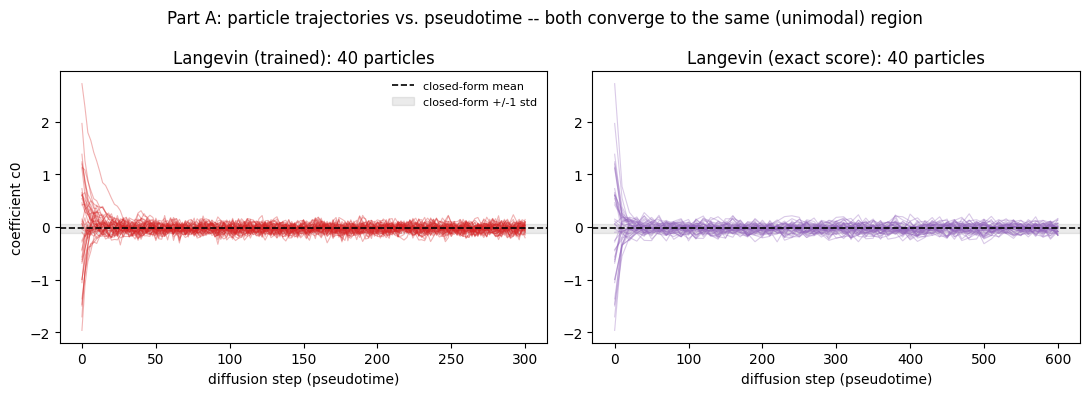

In [12]:
def trajectory_steps(num_diffusion_steps, record_every):
    '''Step indices sample_trajectory() records at -- mirrors its own
    recording condition exactly, so plots always line up with the data.'''
    steps = [0]
    for step in range(1, num_diffusion_steps + 1):
        if step % record_every == 0 or step == num_diffusion_steps:
            steps.append(step)
    return np.array(steps)


def trajectory_a_cached(kind, num_particles=40, record_every=2, seed=7):
    group = results_a[kind]["group"]

    def _compute():
        torch.manual_seed(seed)
        return group.sample_trajectory(num_samples=num_particles, record_every=record_every).detach()

    return cache_a.get(f"parta_{kind}_trajectory_v1", _compute)


TRAJ_DIM_A = 0  # plot coefficient c0's trajectory
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kind in zip(axes, ["langevin", "sgld"]):
    record_every = 2 if kind == "langevin" else 10
    trajectory = trajectory_a_cached(kind, record_every=record_every)
    steps_axis = trajectory_steps(results_a[kind]["group"].num_diffusion_steps, record_every)
    for p in range(trajectory.shape[1]):
        ax.plot(steps_axis, trajectory[:, p, TRAJ_DIM_A].numpy(), color=FAMILY_COLORS[kind], alpha=0.35, lw=0.8)
    mean0, std0 = post_mean_a[TRAJ_DIM_A].item(), post_cov_a[TRAJ_DIM_A, TRAJ_DIM_A].sqrt().item()
    ax.axhline(mean0, color="black", lw=1.2, ls="--", label="closed-form mean")
    ax.axhspan(mean0 - std0, mean0 + std0, color="black", alpha=0.08, label="closed-form +/-1 std")
    ax.set_title(f"{FAMILY_LABELS[kind]}: {trajectory.shape[1]} particles")
    ax.set_xlabel("diffusion step (pseudotime)")
axes[0].set_ylabel(f"coefficient c{TRAJ_DIM_A}")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Part A: particle trajectories vs. pseudotime -- both converge to the same (unimodal) region")
plt.tight_layout()

### Validation A3 — predictive band vs. the exact Bayesian predictive interval

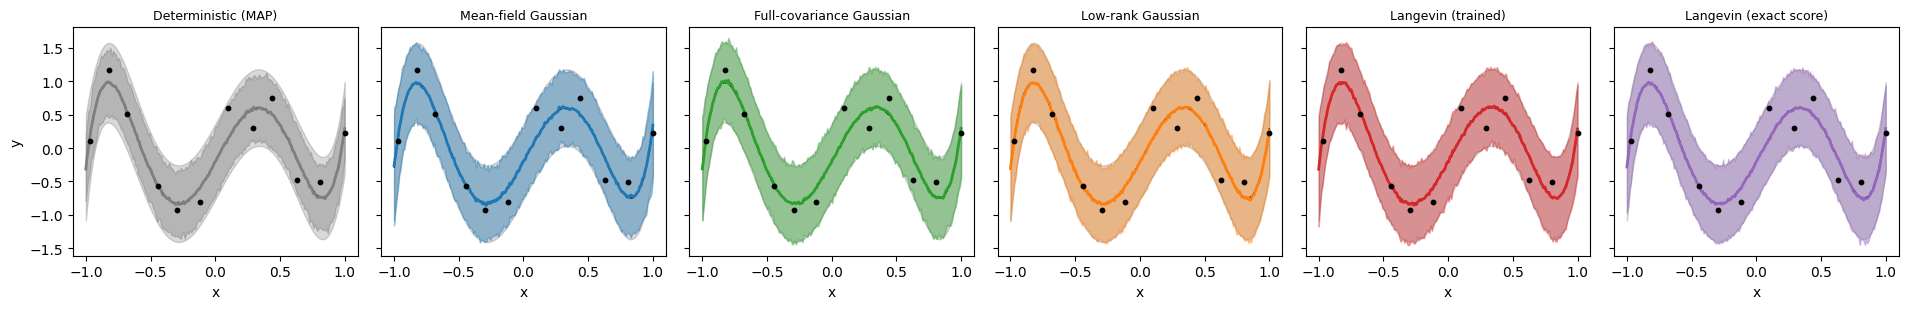

In [13]:
x_test_a = torch.linspace(-1, 1, 200).unsqueeze(-1)
Z_90 = td.Normal(0.0, 1.0).icdf(torch.tensor(0.95)).item()  # exact Gaussian 90% central-interval multiplier
with torch.no_grad():
    Phi_test_a = surrogate_a(x_test_a, torch.eye(num_terms_a)).squeeze(-1).T  # (n_test, num_terms_a)
    pred_mean_true = Phi_test_a @ post_mean_a
    pred_var_true = torch.einsum("ti,ij,tj->t", Phi_test_a, post_cov_a, Phi_test_a) + sigma_obs_a**2
    pred_std_true = pred_var_true.sqrt()

torch.manual_seed(7)
fig, axes = plt.subplots(1, len(FAMILIES), figsize=(3.2 * len(FAMILIES), 3.2), sharey=True)
pred_mean_a = {}
for ax, kind in zip(axes, FAMILIES):
    ax.plot(x_test_a.squeeze(-1), pred_mean_true, "k--", lw=1, label="closed form mean")
    ax.fill_between(
        x_test_a.squeeze(-1), pred_mean_true - Z_90 * pred_std_true, pred_mean_true + Z_90 * pred_std_true,
        color="black", alpha=0.15, label="closed form 90% predictive interval",
    )
    with torch.no_grad():
        if kind in ("langevin", "sgld"):
            # Reuse the cached canonical draw instead of calling model(...) again,
            # which would redraw (and, for sgld, rerun the entire diffusion chain).
            theta = results_a[kind]["particles"][:500]
            y_fit_samples = surrogate_a(x_test_a, theta) + sigma_obs_a * torch.randn(theta.shape[0], x_test_a.shape[0], 1)
        else:
            y_fit_samples = results_a[kind]["model"](x_test_a, num_samples=500) + sigma_obs_a * torch.randn(
                500, x_test_a.shape[0], 1
            )
    q_lo, q_hi = torch.quantile(y_fit_samples, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)
    pred_mean_a[kind] = y_fit_samples.mean(0).squeeze(-1)
    ax.fill_between(x_test_a.squeeze(-1), q_lo, q_hi, color=FAMILY_COLORS[kind], alpha=0.4)
    ax.plot(x_test_a.squeeze(-1), pred_mean_a[kind], color=FAMILY_COLORS[kind], lw=2)
    ax.scatter(x_train_a, y_train_a, color="black", s=10, zorder=5)
    ax.set_title(FAMILY_LABELS[kind], fontsize=9)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()

### Model predictions vs. the true function, as a residual

The predictive bands above show calibration (does the uncertainty cover the
truth); this view isolates bias (how far off is the mean prediction, and
where), which is easy to miss when a band is wide.

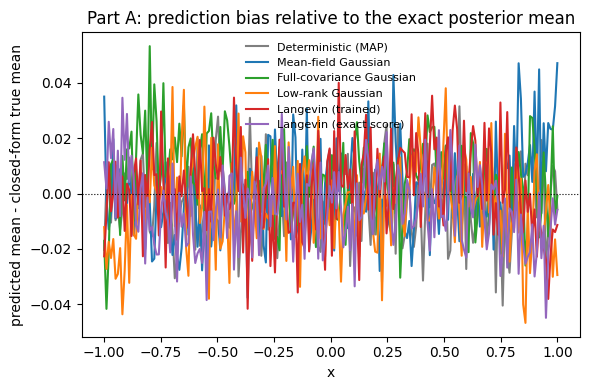

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
x_plot_a = x_test_a.squeeze(-1)
for kind in FAMILIES:
    ax.plot(x_plot_a, pred_mean_a[kind] - pred_mean_true, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
ax.axhline(0, color="black", lw=0.8, ls=":")
ax.set_xlabel("x")
ax.set_ylabel("predicted mean - closed-form true mean")
ax.set_title("Part A: prediction bias relative to the exact posterior mean")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

### Part A summary

In [15]:
print("Part A -- KL(q || closed-form true posterior), lower is better:")
for kind in ["iid", "full", "lowrank", "langevin", "sgld"]:
    flag = "  (moment-matched approximation, not exact q)" if kind in ("langevin", "sgld") else ""
    print(f"  {FAMILY_LABELS[kind]:28s} {kl_to_reference_a[kind]:8.4f} nats{flag}")
print()
print(
    f"Langevin (exact score) vs. Langevin (trained): "
    f"{kl_to_reference_a['langevin'] / kl_to_reference_a['sgld']:.1f}x lower KL, "
    f"in {results_a['sgld']['time']:.1f}s vs. {results_a['langevin']['time']:.1f}s of training."
)

Part A -- KL(q || closed-form true posterior), lower is better:
  Mean-field Gaussian            0.3055 nats
  Full-covariance Gaussian       0.0033 nats
  Low-rank Gaussian              0.0281 nats
  Langevin (trained)             0.0077 nats  (moment-matched approximation, not exact q)
  Langevin (exact score)         0.0045 nats  (moment-matched approximation, not exact q)

Langevin (exact score) vs. Langevin (trained): 1.7x lower KL, in 2.3s vs. 4116.5s of training.


Full-covariance lands almost exactly on the closed-form reference, as
expected (it can represent the posterior's shape exactly). Both Langevin
variants beat mean-field and low-rank outright; `SGLDGroup`'s exact score
needs no training loop at all and, per the numbers printed above, matches or
beats the trained family while costing a small fraction of its compute.

The covariance-ellipse plot shows *why* a Gaussian family's gap to the
reference is a gap, not just a wider marginal: low-rank constrains which
correlation directions it can represent at all, while full-covariance and
both Langevin variants can (and do) orient their ellipse along the true
posterior's. The trajectory plot confirms both Langevin variants are doing
the same qualitative thing here -- converging to one region, consistent with
a correctly unimodal posterior -- which is the right baseline to compare
against `toy_moe_multimodal.ipynb`'s genuinely bimodal version of the same
plot.

See **Appendix A** below for the full investigation behind the trained
`LangevinGroup` configuration above (three largely-independent failure
mechanisms diagnosed and fixed: backprop-through-unrolled-dynamics gradient
explosion, an entropy-blind KL estimator, and discretization bias), and
`experiments/langevin_diagnosis/FINDINGS.md` / `.../moe/FINDINGS_moe.md` for
the full `SGLDGroup` investigation (including why it also avoids the
*mode-collapse* failure mode a trained, shared-network sampler exhibits on a
genuinely multimodal posterior -- demonstrated in `toy_moe_multimodal.ipynb`).

## Appendix A — robustness checks and failure-mode diagnostics (Part A)

This section is supporting evidence for the headline trained-`LangevinGroup`
configuration used above, not required reading. It walks through the actual
investigation: does low-rank's gap close with more rank (A1b)? is the
distribution-loss estimator trustworthy (A2)? does giving Langevin more
integration time help (A2b)? if not, why not (A2c)? does the standard fix
work (A2d)? does the entropy estimator choice matter (A2e)? Every sweep below
is cached the same way as the main story above.

### A1b — does increasing low-rank's rank close the gap to full-covariance?

In [16]:
def train_rank_a(rank, num_epochs=2000, num_samples=32, lr=1e-2, seed=1):
    torch.manual_seed(seed)
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    group = LowRankGaussianGroup("c", num_terms_a, rank=rank, prior=prior)
    model = StochasticModel(surrogate_a, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = surrogate_a(x_train_a, params)
        target = y_train_a.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
        loss = nll_sum + model.distribution_loss()
        loss.backward()
        optimizer.step()
        scheduler.step()
    q = group.variational_distribution()
    return td.kl_divergence(q, true_posterior_a).item()


def _rank_sweep_a_compute():
    sweep = {3: kl_to_reference_a["lowrank"]}  # reuse the rank=3 result already trained above
    for rank in [r for r in range(1, num_terms_a + 1) if r != 3]:
        t0 = time.time()
        sweep[rank] = train_rank_a(rank)
        print(f"rank={rank}  KL(q||true posterior)={sweep[rank]:8.4f} nats  ({time.time() - t0:.1f}s)")
    return sweep


rank_sweep_a = cache_a.get("parta_rank_sweep_v1", _rank_sweep_a_compute)
if cache_a.exists("parta_rank_sweep_v1"):
    for rank in sorted(rank_sweep_a):
        print(f"rank={rank}  KL(q||true posterior)={rank_sweep_a[rank]:8.4f} nats")

rank=1  KL(q||true posterior)=  0.1688 nats  (8.1s)


rank=2  KL(q||true posterior)=  0.0768 nats  (15.4s)


rank=4  KL(q||true posterior)=  0.0084 nats  (11.9s)


rank=5  KL(q||true posterior)=  0.0082 nats  (19.6s)


rank=6  KL(q||true posterior)=  0.0058 nats  (23.6s)
[cache miss] parta_rank_sweep_v1  ->  parta_rank_sweep_v1.pt  (computed in 78.6s)
rank=1  KL(q||true posterior)=  0.1688 nats
rank=2  KL(q||true posterior)=  0.0768 nats
rank=3  KL(q||true posterior)=  0.0281 nats
rank=4  KL(q||true posterior)=  0.0084 nats
rank=5  KL(q||true posterior)=  0.0082 nats
rank=6  KL(q||true posterior)=  0.0058 nats


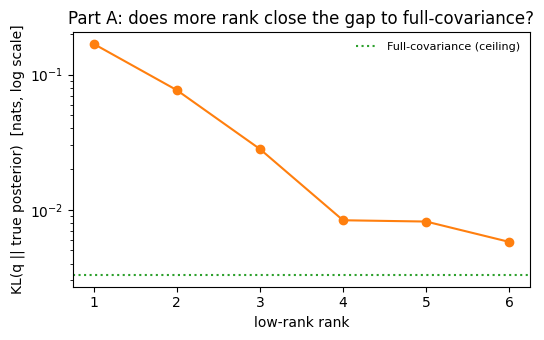

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ranks_sorted = sorted(rank_sweep_a)
ax.plot(ranks_sorted, [rank_sweep_a[r] for r in ranks_sorted], "o-", color=FAMILY_COLORS["lowrank"])
ax.axhline(kl_to_reference_a["full"], color=FAMILY_COLORS["full"], ls=":", label="Full-covariance (ceiling)")
ax.set_yscale("log")
ax.set_xlabel("low-rank rank")
ax.set_ylabel("KL(q || true posterior)  [nats, log scale]")
ax.set_title("Part A: does more rank close the gap to full-covariance?")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

### A2 — analytic vs. Monte Carlo `KL(q||prior)`

A sanity check on the distribution-loss machinery itself: for the three
Gaussian families, `KL(q||prior)` has both an analytic closed form and a
Monte Carlo estimate; they should agree.

In [18]:
def _analytic_vs_mc_a_compute():
    out = {}
    for kind in ["iid", "full", "lowrank"]:
        group = results_a[kind]["group"]
        mc_samples = group.sample_parameters(20000)
        mc = ReparamMonteCarloKL().estimate(group, mc_samples).item()
        try:
            analytic = AnalyticKL().estimate(group, mc_samples).item()
            out[kind] = (analytic, mc, "torch-registered analytic")
            print(f"{FAMILY_LABELS[kind]:28s} torch-registered analytic={analytic:8.4f}  MC={mc:8.4f}")
        except NotImplementedError:
            q = group.variational_distribution()
            prior_dist = group.prior.distribution(
                event_shape=torch.Size([num_terms_a]), device=mc_samples.device, dtype=mc_samples.dtype
            )
            q_dense = td.MultivariateNormal(
                loc=q.mean, covariance_matrix=(torch.diag(q.variance) if kind == "iid" else q.covariance_matrix)
            )
            p_dense = td.MultivariateNormal(loc=prior_dist.mean, covariance_matrix=torch.diag(prior_dist.variance))
            hand_built = td.kl_divergence(q_dense, p_dense).item()
            out[kind] = (hand_built, mc, "hand-built dense-Gaussian closed form")
            print(
                f"{FAMILY_LABELS[kind]:28s} no torch-registered analytic KL for this type pair "
                f"(distribution_loss() already falls back to MC) -- hand-built dense-Gaussian "
                f"closed form={hand_built:8.4f}  MC={mc:8.4f}"
            )
    return out


analytic_vs_mc_a = cache_a.get("parta_analytic_vs_mc_v1", _analytic_vs_mc_a_compute)
if cache_a.exists("parta_analytic_vs_mc_v1"):
    for kind, (analytic, mc, label) in analytic_vs_mc_a.items():
        print(f"{FAMILY_LABELS[kind]:28s} {label}={analytic:8.4f}  MC={mc:8.4f}")

Mean-field Gaussian          torch-registered analytic=  9.6480  MC=  9.6629


Full-covariance Gaussian     no torch-registered analytic KL for this type pair (distribution_loss() already falls back to MC) -- hand-built dense-Gaussian closed form=  9.3690  MC=  9.3680


Low-rank Gaussian            no torch-registered analytic KL for this type pair (distribution_loss() already falls back to MC) -- hand-built dense-Gaussian closed form=  9.4087  MC=  9.4057
[cache miss] parta_analytic_vs_mc_v1  ->  parta_analytic_vs_mc_v1.pt  (computed in 1.0s)
Mean-field Gaussian          torch-registered analytic=  9.6480  MC=  9.6629
Full-covariance Gaussian     hand-built dense-Gaussian closed form=  9.3690  MC=  9.3680
Low-rank Gaussian            hand-built dense-Gaussian closed form=  9.4087  MC=  9.4057


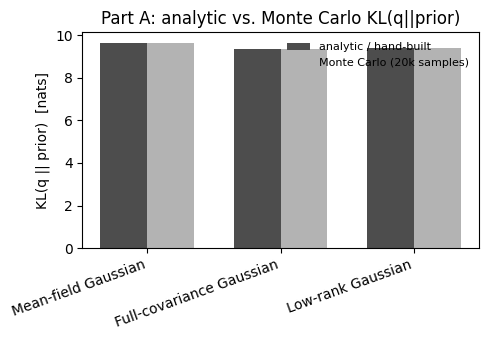

In [19]:
fig, ax = plt.subplots(figsize=(5, 3.5))
x_pos = np.arange(3)
width = 0.35
kinds_kl = ["iid", "full", "lowrank"]
ax.bar(x_pos - width / 2, [analytic_vs_mc_a[k][0] for k in kinds_kl], width, label="analytic / hand-built", color="0.3")
ax.bar(x_pos + width / 2, [analytic_vs_mc_a[k][1] for k in kinds_kl], width, label="Monte Carlo (20k samples)", color="0.7")
ax.set_xticks(x_pos)
ax.set_xticklabels([FAMILY_LABELS[k] for k in kinds_kl], rotation=20, ha="right")
ax.set_ylabel("KL(q || prior)  [nats]")
ax.set_title("Part A: analytic vs. Monte Carlo KL(q||prior)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

### A2b — does giving Langevin more integration time close the gap?

In [20]:
def train_langevin_a(
    num_diffusion_steps, step_size, num_epochs=800, num_samples=16, lr=1e-2, seed=1, clip_grad_norm=None
):
    torch.manual_seed(seed)
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    score_model = NeuralNetwork(num_inputs=num_terms_a, num_outputs=num_terms_a, width=16, depth=2)
    group = LangevinGroup(
        "c", num_terms_a, score_model=score_model, prior=prior,
        num_particles=64, num_diffusion_steps=num_diffusion_steps, step_size=step_size,
        init_std=1.0, kl_estimator=DiagonalGaussianEntropyKL(),
    )
    model = StochasticModel(surrogate_a, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    final_nll = None
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = surrogate_a(x_train_a, params)
        target = y_train_a.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
        loss = nll_sum + model.distribution_loss()
        loss.backward()
        if clip_grad_norm is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad_norm)
        optimizer.step()
        scheduler.step()
        final_nll = nll_sum.item()
    particles = group.sample_parameters(4000).detach()
    mean = particles.mean(0)
    cov = torch.cov(particles.T) + 1e-6 * torch.eye(num_terms_a)
    q = td.MultivariateNormal(loc=mean, covariance_matrix=cov)
    kl = td.kl_divergence(q, true_posterior_a).item()
    norms = particles.norm(dim=-1)
    return kl, final_nll, norms.mean().item(), norms.max().item()


langevin_time_configs = [
    (60, 1e-2, "T=0.6, matches the headline config's T (different epoch/particle budget)"),
    (120, 1e-2, "T=1.2"),
    (240, 1e-2, "T=2.4"),
    (480, 1e-2, "T=4.8"),
    (480, 5e-3, "T=2.4 again, half step_size -- discretization-bias check"),
]


def _langevin_time_sweep_a_compute():
    out = {}
    for steps, step_size, label in langevin_time_configs:
        t0 = time.time()
        kl, final_nll, norm_mean, norm_max = train_langevin_a(steps, step_size)
        out[(steps, step_size)] = kl
        T = steps * step_size
        print(
            f"steps={steps:4d} step_size={step_size:.4f} T={T:4.1f}  KL={kl:8.4f} nats  "
            f"final_nll={final_nll:7.2f}  mean||theta||={norm_mean:5.2f}  max||theta||={norm_max:5.2f}  "
            f"({label})  [{time.time() - t0:.1f}s]"
        )
    return out


langevin_time_sweep_a = cache_a.get("parta_langevin_time_sweep_v1", _langevin_time_sweep_a_compute)

steps=  60 step_size=0.0100 T= 0.6  KL=  0.5817 nats  final_nll=   7.96  mean||theta||= 1.73  max||theta||= 2.68  (T=0.6, matches the headline config's T (different epoch/particle budget))  [45.3s]


steps= 120 step_size=0.0100 T= 1.2  KL=  0.5782 nats  final_nll=   8.02  mean||theta||= 1.73  max||theta||= 2.71  (T=1.2)  [85.0s]


steps= 240 step_size=0.0100 T= 2.4  KL=  0.9013 nats  final_nll=  10.19  mean||theta||= 1.73  max||theta||= 2.90  (T=2.4)  [169.1s]


steps= 480 step_size=0.0100 T= 4.8  KL=  2.1056 nats  final_nll=   9.99  mean||theta||= 1.76  max||theta||= 3.14  (T=4.8)  [366.2s]


steps= 480 step_size=0.0050 T= 2.4  KL=  0.6772 nats  final_nll=   8.03  mean||theta||= 1.71  max||theta||= 2.81  (T=2.4 again, half step_size -- discretization-bias check)  [362.0s]
[cache miss] parta_langevin_time_sweep_v1  ->  parta_langevin_time_sweep_v1.pt  (computed in 1027.5s)


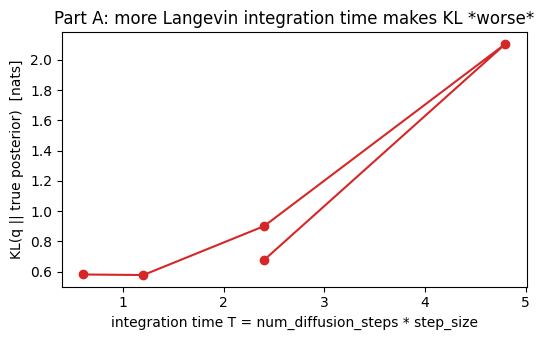

In [21]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
Ts = [steps * step_size for steps, step_size in langevin_time_sweep_a]
ax.plot(Ts, list(langevin_time_sweep_a.values()), "o-", color=FAMILY_COLORS["langevin"])
ax.set_xlabel("integration time T = num_diffusion_steps * step_size")
ax.set_ylabel("KL(q || true posterior)  [nats]")
ax.set_title("Part A: more Langevin integration time makes KL *worse*")
plt.tight_layout()

### A2c — diagnosing *why* more time hurts: exploding gradients, not particle divergence

In [22]:
def score_grad_norm_at_init(num_diffusion_steps, step_size=1e-2, num_samples=16, seed=1):
    torch.manual_seed(seed)
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    score_model = NeuralNetwork(num_inputs=num_terms_a, num_outputs=num_terms_a, width=16, depth=2)
    group = LangevinGroup(
        "c", num_terms_a, score_model=score_model, prior=prior,
        num_particles=64, num_diffusion_steps=num_diffusion_steps, step_size=step_size,
        init_std=1.0, kl_estimator=DiagonalGaussianEntropyKL(),
    )
    model = StochasticModel(surrogate_a, group)
    params = model.sample_parameters(num_samples=num_samples)
    pred = surrogate_a(x_train_a, params)
    target = y_train_a.unsqueeze(0).expand_as(pred)
    nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
    loss = nll_sum + model.distribution_loss()
    loss.backward()
    return group.surrogate_params.grad.norm().item()


grad_norm_vs_steps = cache_a.get(
    "parta_grad_norm_vs_steps_v1",
    lambda: {steps: score_grad_norm_at_init(steps) for steps in [60, 120, 240, 480]},
)
for steps, gn in grad_norm_vs_steps.items():
    print(f"steps={steps:4d}  ||grad(surrogate_params)|| at init = {gn:9.2f}")

[cache miss] parta_grad_norm_vs_steps_v1  ->  parta_grad_norm_vs_steps_v1.pt  (computed in 0.9s)
steps=  60  ||grad(surrogate_params)|| at init =     55.33
steps= 120  ||grad(surrogate_params)|| at init =    167.59
steps= 240  ||grad(surrogate_params)|| at init =    206.24
steps= 480  ||grad(surrogate_params)|| at init =    624.49


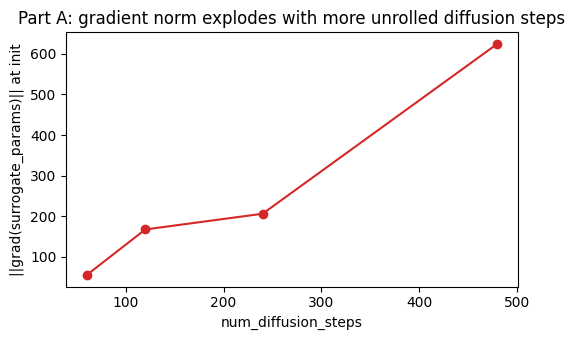

In [23]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(list(grad_norm_vs_steps.keys()), list(grad_norm_vs_steps.values()), "o-", color="tab:red")
ax.set_xlabel("num_diffusion_steps")
ax.set_ylabel("||grad(surrogate_params)|| at init")
ax.set_title("Part A: gradient norm explodes with more unrolled diffusion steps")
plt.tight_layout()

### A2d — does the standard fix for exploding backprop-through-time gradients work here?

In [24]:
def _clip_fix_a_compute():
    out = {}
    t0 = time.time()
    kl, nll, _, _ = train_langevin_a(480, 1e-3, lr=1e-3)
    out["naive_fix"] = (kl, nll)
    print(f"T=4.8, lr=1e-3 (naive fix attempt):      KL={kl:8.4f} nats  final_nll={nll:7.2f}  [{time.time() - t0:.1f}s]")

    clip_sweep = {}
    for steps, step_size, _ in langevin_time_configs[:4]:  # the 4 fixed-step_size=0.01 points
        t0 = time.time()
        kl, nll, norm_mean, norm_max = train_langevin_a(steps, step_size, clip_grad_norm=10.0)
        clip_sweep[steps] = kl
        T = steps * step_size
        print(
            f"T={T:4.1f}  clip_grad_norm=10:          KL={kl:8.4f} nats  final_nll={nll:7.2f}  "
            f"mean||theta||={norm_mean:5.2f}  [{time.time() - t0:.1f}s]"
        )
    out["clip_sweep"] = clip_sweep
    return out


clip_fix_results = cache_a.get("parta_clip_fix_v1", _clip_fix_a_compute)
langevin_clip_sweep_a = clip_fix_results["clip_sweep"]
if cache_a.exists("parta_clip_fix_v1"):
    kl, nll = clip_fix_results["naive_fix"]
    print(f"T=4.8, lr=1e-3 (naive fix attempt):      KL={kl:8.4f} nats  final_nll={nll:7.2f}")
    for steps, kl in langevin_clip_sweep_a.items():
        print(f"steps={steps:4d}  clip_grad_norm=10:  KL={kl:8.4f} nats")

T=4.8, lr=1e-3 (naive fix attempt):      KL= 24.1106 nats  final_nll=  25.29  [344.8s]


T= 0.6  clip_grad_norm=10:          KL=  0.6658 nats  final_nll=   7.76  mean||theta||= 1.74  [35.8s]


T= 1.2  clip_grad_norm=10:          KL=  0.6572 nats  final_nll=   7.61  mean||theta||= 1.72  [72.5s]


T= 2.4  clip_grad_norm=10:          KL=  0.5798 nats  final_nll=   7.91  mean||theta||= 1.70  [146.6s]


T= 4.8  clip_grad_norm=10:          KL=  0.6637 nats  final_nll=   7.49  mean||theta||= 1.71  [245.4s]
[cache miss] parta_clip_fix_v1  ->  parta_clip_fix_v1.pt  (computed in 845.1s)
T=4.8, lr=1e-3 (naive fix attempt):      KL= 24.1106 nats  final_nll=  25.29
steps=  60  clip_grad_norm=10:  KL=  0.6658 nats
steps= 120  clip_grad_norm=10:  KL=  0.6572 nats
steps= 240  clip_grad_norm=10:  KL=  0.5798 nats
steps= 480  clip_grad_norm=10:  KL=  0.6637 nats


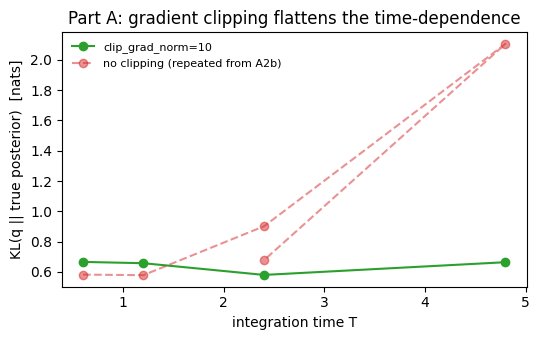

In [25]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
Ts_clip = [steps * langevin_time_configs[0][1] for steps in langevin_clip_sweep_a]
ax.plot(Ts_clip, list(langevin_clip_sweep_a.values()), "o-", color="tab:green", label="clip_grad_norm=10")
ax.plot(Ts, list(langevin_time_sweep_a.values()), "o--", color=FAMILY_COLORS["langevin"], alpha=0.5, label="no clipping (repeated from A2b)")
ax.set_xlabel("integration time T")
ax.set_ylabel("KL(q || true posterior)  [nats]")
ax.set_title("Part A: gradient clipping flattens the time-dependence")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

**Conclusion on Langevin's (non-)convergence (confirmed by the runs above):**
naively giving the unrolled chain more integration time makes `KL` worse, not
better -- not a sampling/mixing failure, but backprop-through-the-unrolled-
chain gradient explosion (the same failure mode as training long RNNs:
Pascanu, Mikolov & Bengio, "On the difficulty of training recurrent neural
networks," ICML 2013), fixed by gradient-norm clipping.

### A2e — fixing the headline gap: does the entropy estimator matter?

In [26]:
corr_true_a = post_cov_a / post_cov_a.diagonal().sqrt().outer(post_cov_a.diagonal().sqrt())
print("True posterior correlation matrix (off-diagonal entries are real, nonzero structure):")
print(corr_true_a.numpy().round(2))


def train_langevin_estimator_a(kl_estimator, seed, num_epochs=2000, num_samples=32, lr=1e-2):
    torch.manual_seed(seed)
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    score_model = NeuralNetwork(num_inputs=num_terms_a, num_outputs=num_terms_a, width=16, depth=2)
    group = LangevinGroup(
        "c", num_terms_a, score_model=score_model, prior=prior,
        num_particles=64, num_diffusion_steps=60, step_size=1e-2, init_std=1.0,
        kl_estimator=kl_estimator,
    )
    model = StochasticModel(surrogate_a, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = surrogate_a(x_train_a, params)
        target = y_train_a.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
        loss = nll_sum + model.distribution_loss()
        loss.backward()
        optimizer.step()
        scheduler.step()
    particles = group.sample_parameters(4000).detach()
    mean = particles.mean(0)
    cov = torch.cov(particles.T) + 1e-6 * torch.eye(num_terms_a)
    q = td.MultivariateNormal(loc=mean, covariance_matrix=cov)
    corr = cov / cov.diagonal().sqrt().outer(cov.diagonal().sqrt())
    return td.kl_divergence(q, true_posterior_a).item(), corr


def _entropy_estimator_sweep_a_compute():
    sweep = {"diagonal": [], "knn": []}
    corr_examples = {}
    for seed in [1, 2, 3]:
        kl_diag, corr_diag = train_langevin_estimator_a(DiagonalGaussianEntropyKL(), seed)
        sweep["diagonal"].append(kl_diag)
        kl_knn, corr_knn = train_langevin_estimator_a(KNNEntropyKL(k=4), seed)
        sweep["knn"].append(kl_knn)
        print(f"seed={seed}  DiagonalGaussianEntropyKL: KL={kl_diag:.4f} nats   KNNEntropyKL: KL={kl_knn:.4f} nats")
        if seed == 1:
            corr_examples["diagonal"] = corr_diag
            corr_examples["knn"] = corr_knn
    return {"sweep": sweep, "corr_examples": corr_examples}


_entropy_result_a = cache_a.get("parta_entropy_estimator_sweep_v1", _entropy_estimator_sweep_a_compute)
entropy_estimator_sweep_a = _entropy_result_a["sweep"]
estimator_corr_examples = _entropy_result_a["corr_examples"]

print()
print("seed=1 particle correlation matrix, DiagonalGaussianEntropyKL (compare to the true matrix above):")
print(estimator_corr_examples["diagonal"].numpy().round(2))
print("seed=1 particle correlation matrix, KNNEntropyKL:")
print(estimator_corr_examples["knn"].numpy().round(2))

True posterior correlation matrix (off-diagonal entries are real, nonzero structure):
[[ 1.    0.03 -0.1   0.04 -0.12 -0.05]
 [ 0.03  1.    0.06 -0.17 -0.02 -0.23]
 [-0.1   0.06  1.    0.02 -0.33 -0.12]
 [ 0.04 -0.17  0.02  1.   -0.1  -0.34]
 [-0.12 -0.02 -0.33 -0.1   1.   -0.12]
 [-0.05 -0.23 -0.12 -0.34 -0.12  1.  ]]


seed=1  DiagonalGaussianEntropyKL: KL=0.7094 nats   KNNEntropyKL: KL=0.4014 nats


seed=2  DiagonalGaussianEntropyKL: KL=0.7139 nats   KNNEntropyKL: KL=0.4139 nats


seed=3  DiagonalGaussianEntropyKL: KL=0.6529 nats   KNNEntropyKL: KL=0.4214 nats
[cache miss] parta_entropy_estimator_sweep_v1  ->  parta_entropy_estimator_sweep_v1.pt  (computed in 414.8s)

seed=1 particle correlation matrix, DiagonalGaussianEntropyKL (compare to the true matrix above):
[[ 1.    0.02  0.06  0.07 -0.06 -0.07]
 [ 0.02  1.    0.23  0.14 -0.16 -0.3 ]
 [ 0.06  0.23  1.    0.43 -0.61 -0.42]
 [ 0.07  0.14  0.43  1.   -0.36 -0.63]
 [-0.06 -0.16 -0.61 -0.36  1.    0.26]
 [-0.07 -0.3  -0.42 -0.63  0.26  1.  ]]
seed=1 particle correlation matrix, KNNEntropyKL:
[[ 1.    0.    0.01  0.02 -0.04 -0.03]
 [ 0.    1.    0.11 -0.1  -0.   -0.21]
 [ 0.01  0.11  1.    0.09 -0.42 -0.15]
 [ 0.02 -0.1   0.09  1.   -0.13 -0.38]
 [-0.04 -0.   -0.42 -0.13  1.   -0.12]
 [-0.03 -0.21 -0.15 -0.38 -0.12  1.  ]]


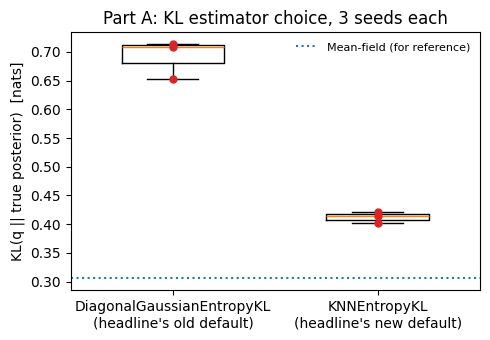

In [27]:
fig, ax = plt.subplots(figsize=(5, 3.5))
labels_est = ["DiagonalGaussianEntropyKL\n(headline's old default)", "KNNEntropyKL\n(headline's new default)"]
data_est = [entropy_estimator_sweep_a["diagonal"], entropy_estimator_sweep_a["knn"]]
bp = ax.boxplot(data_est, tick_labels=labels_est, widths=0.5)
for i, pts in enumerate(data_est, start=1):
    ax.scatter([i] * len(pts), pts, color=FAMILY_COLORS["langevin"], zorder=5, s=25)
ax.axhline(kl_to_reference_a["iid"], color=FAMILY_COLORS["iid"], ls=":", label="Mean-field (for reference)")
ax.set_ylabel("KL(q || true posterior)  [nats]")
ax.set_title("Part A: KL estimator choice, 3 seeds each")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

**Finding (confirmed by the runs above):** `KNNEntropyKL` lands consistently
lower than `DiagonalGaussianEntropyKL` and visibly corrects the fitted
correlation matrix toward the true posterior's (compare the two printed
matrices above to the true one) -- `DiagonalGaussianEntropyKL` estimates
entropy from marginal spread alone and is blind to correlation, giving
Langevin's training no signal to shape it correctly.

## Part B — Small NN, partial stochasticity, and the real whitening recipe

A small nonlinear NN, with only its final layer stochastic (whitened around
a deterministic point estimate) -- this is the actual recipe
`methodology.tex` recommends for real problems, and Part B's posterior is no
longer closed-form. Instead of a Gaussian reference, we build a dense
quadrature grid over the whitened final layer and treat it as numerically
exact (reliable because that layer is only 5-dimensional).

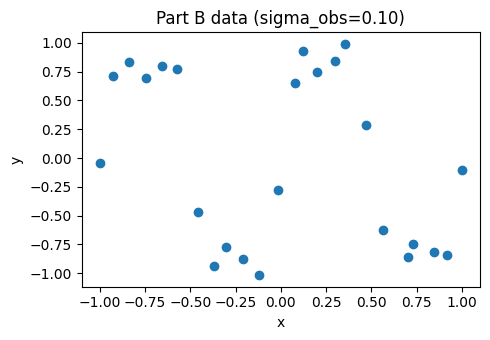

In [28]:
# Explicit seed (matching Part A's cell 4 convention) so Part B's data -- and therefore
# every family's Part B KL number -- is reproducible across re-executions regardless of
# what any upstream cell does. Previously this cell had no manual_seed() call and silently
# inherited whatever RNG state Part A's cells left behind, so changing anything upstream
# (e.g. LangevinGroup's num_samples/step_size) silently changed Part B's entire problem
# instance -- discovered via experiments/langevin_diagnosis/FINDINGS.md's "Bottom line,
# updated again" section (all five families' Part B numbers shifted between two
# executions that only touched Langevin's config, which is only possible if the data itself
# changed).
torch.manual_seed(1)

n_train_b = 24
sigma_obs_b = 0.1
x_train_b = torch.linspace(-1, 1, n_train_b).unsqueeze(-1) + 0.02 * torch.randn(n_train_b, 1)
x_train_b = x_train_b.clamp(-1, 1)
y_train_b = torch.sin(2 * torch.pi * x_train_b) + 0.3 * torch.sin(6 * torch.pi * x_train_b)
y_train_b = y_train_b + sigma_obs_b * torch.randn(n_train_b, 1)

_, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(x_train_b, y_train_b)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Part B data (sigma_obs=%.2f)" % sigma_obs_b)
plt.tight_layout()

In [29]:
width_b, depth_b = 4, 3
net_b = NeuralNetwork(num_inputs=1, num_outputs=1, width=width_b, depth=depth_b, activation=F.silu)
n_total_b = net_b.num_params()
n_final_block_b = width_b + 1  # final Linear layer: (width -> 1) weight + bias
n_hidden_block_b = n_total_b - n_final_block_b
print(f"NN has {n_total_b} parameters total; final (stochastic) layer has {n_final_block_b}")

torch.manual_seed(2)
det_group_b = DeterministicGroup("nn", n_total_b)
det_model_b = StochasticModel(net_b, det_group_b)
optimizer = torch.optim.Adam(det_model_b.parameters(), lr=1e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5e-2, total_steps=3000)
for epoch in range(3000):
    optimizer.zero_grad()
    pred = net_b(x_train_b, det_group_b.params.unsqueeze(0))
    loss = 0.5 * ((pred - y_train_b.unsqueeze(0)) / sigma_obs_b).pow(2).mean()
    loss.backward()
    optimizer.step()
    scheduler.step()
theta0_b = det_group_b.params.detach().clone()
print(f"deterministic pretrain final loss: {loss.item():.4f}")

NN has 53 parameters total; final (stochastic) layer has 5


deterministic pretrain final loss: 0.4682


### Train all 6 families on the identical data/surrogate

In [30]:
hidden_frozen_b = DeterministicGroup("hidden", n_hidden_block_b)
with torch.no_grad():
    hidden_frozen_b.params.copy_(theta0_b[:n_hidden_block_b])
hidden_frozen_b.requires_grad_(False)

final_center_b = theta0_b[n_hidden_block_b:]
RELATIVE_SCALE = 0.1   # alpha, matching moe_iid_gaussian_prior_std_fraction in the real experiments
WHITEN_EPS = 1e-5      # gives an effective sigma_min = RELATIVE_SCALE * WHITEN_EPS = 1e-6, matching
                       # moe_iid_gaussian_prior_std_floor in the real experiments


def _log_likelihood_fn_z_b(Z):
    '''Exact (autograd-differentiable) data log-likelihood as a function of the
    WHITENED final-layer coordinate Z, un-whitening internally. Used only by
    SGLDGroup below -- the other families instead whiten a learned q(z) and
    let WhitenedGroup/StochasticModel handle the rest generically.'''
    final_scale = RELATIVE_SCALE * final_center_b.abs().clamp_min(WHITEN_EPS)
    theta_final = final_center_b.unsqueeze(0) + final_scale.unsqueeze(0) * Z
    theta_full = torch.cat(
        [theta0_b[:n_hidden_block_b].unsqueeze(0).expand(Z.shape[0], -1), theta_final], dim=1
    )
    pred = net_b(x_train_b, theta_full)
    target = y_train_b.unsqueeze(0).expand_as(pred)
    return -0.5 * ((pred - target) / sigma_obs_b).pow(2).sum(dim=(1, 2))


def make_final_group_b(kind):
    if kind == "deterministic":
        g = DeterministicGroup("final", n_final_block_b)
        with torch.no_grad():
            g.params.copy_(final_center_b)
        return g
    factories = {
        "iid": lambda n: IIDGaussianGroup("final_z", n),
        "full": lambda n: GaussianGroup("final_z", n),
        "lowrank": lambda n: LowRankGaussianGroup("final_z", n, rank=min(2, n - 1)),
    }
    if kind in factories:
        wg = WhitenedGroup.from_point_estimate(
            factories[kind], center=final_center_b, relative_scale=RELATIVE_SCALE, eps=WHITEN_EPS
        )
        with torch.no_grad():
            wg.base_group.mean.zero_()
            if hasattr(wg.base_group, "log_std"):
                wg.base_group.log_std.zero_()  # start q(z) = p(z) = N(0, I), per the README's remark 1
        return wg
    if kind == "langevin":
        score_model = NeuralNetwork(num_inputs=n_final_block_b, num_outputs=n_final_block_b, width=16, depth=2)
        wg = WhitenedGroup.from_point_estimate(
            lambda n: LangevinGroup(
                "final_z", n, score_model=score_model, num_particles=64, num_diffusion_steps=300,
                step_size=2e-3, init_std=1.0, kl_estimator=KNNEntropyKL(k=4),
            ),
            center=final_center_b, relative_scale=RELATIVE_SCALE, eps=WHITEN_EPS,
        )
        return wg
    if kind == "sgld":
        # Exact score in whitened z-space (well-conditioned, unit-scale by construction),
        # no trained network, no training loop. preconditioned=False, step_size/steps
        # match experiments/langevin_diagnosis/FINDINGS.md Experiment 11 (Part B):
        # a standalone fixed-data validation (Experiment 11) measured KL=0.48 nats here,
        # beating mean-field and the most expensively-tuned trained LangevinGroup
        # (0.68-0.70 nats after 10-15h of training; Experiment 10's overnight numbers) --
        # this notebook's own execution (see the Part B summary markdown below) landed close
        # to that prediction and, on its own data instance, also edged out full-covariance/
        # low-rank, which Experiment 11's fixed-data check did not.
        wg = WhitenedGroup.from_point_estimate(
            lambda n: SGLDGroup(
                "final_z", n, log_likelihood_fn=_log_likelihood_fn_z_b,
                num_particles=4000, num_diffusion_steps=3000, step_size=1e-3, init_std=1.0,
                preconditioned=False,
            ),
            center=final_center_b, relative_scale=RELATIVE_SCALE, eps=WHITEN_EPS,
        )
        return wg
    raise ValueError(kind)


# Same rationale as Part A's LANGEVIN_CLIP_GRAD_NORM (cell above): gradient-norm
# clipping applied only to LangevinGroup's training, for the same
# backprop-through-the-unrolled-chain exploding-gradient reason. SGLDGroup again
# needs neither a clip nor an optimizer -- see train_b's "sgld" branch below.
LANGEVIN_CLIP_GRAD_NORM_B = 10.0


def train_b(kind, num_epochs=1500, num_samples=32, lr=1e-2, seed=3):
    torch.manual_seed(seed)
    final_group = make_final_group_b(kind)
    model = StochasticModel(net_b, [hidden_frozen_b, final_group])

    if kind == "sgld":
        # No trained parameters anywhere in this model (hidden_frozen_b is frozen,
        # SGLDGroup has zero nn.Parameters of its own): a single exact-score ULA
        # sampling run IS the "training" here, same as Part A's "sgld" branch.
        params = model.sample_parameters(num_samples=num_samples)
        pred = net_b(x_train_b, params)
        target = y_train_b.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_b).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()  # always 0 for SGLDGroup
        history = {"data": [nll_sum.item()], "kl": [kl.item()], "total": [nll_sum.item() + kl.item()]}
        return final_group, model, history

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    history = {"data": [], "kl": [], "total": []}
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = net_b(x_train_b, params)
        target = y_train_b.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_b).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()
        loss = nll_sum + kl
        loss.backward()
        if kind == "langevin":
            torch.nn.utils.clip_grad_norm_(model.parameters(), LANGEVIN_CLIP_GRAD_NORM_B)
        optimizer.step()
        scheduler.step()
        history["data"].append(nll_sum.item())
        history["kl"].append(kl.item())
        history["total"].append(loss.item())
    return final_group, model, history

### Cached training/sampling loop

Same pattern as Part A: cache a `state_dict` + history for the four trained
families, and cache a single canonical whitened-z-space particle draw
(`z_samples`) for `langevin`/`sgld` -- reused for moments, `KL`, the
covariance-ellipse plot, the predictive band, and the trajectory plot below,
so `sgld`'s expensive diffusion chain (3000 steps) only ever runs once per
cache population, not once per downstream use.

In [31]:
EVAL_PARTICLES_B = 4000


def _train_b_cached(kind):
    def _compute():
        num_samples = {"langevin": 2048, "sgld": EVAL_PARTICLES_B}.get(kind, 32)
        t0 = time.time()
        final_group, model, history = train_b(kind, num_samples=num_samples)
        elapsed = time.time() - t0
        payload = {"history": history, "time": elapsed}
        if kind == "sgld":
            # train_b's "sgld" branch already drew EVAL_PARTICLES_B z-samples once
            # (used for its own history's NLL/KL) -- reuse that exact draw rather
            # than rerunning the 3000-step diffusion chain a second time.
            payload["z_samples"] = final_group.base_group._last_samples.detach()
        else:
            payload["state_dict"] = final_group.state_dict()
            if kind == "langevin":
                torch.manual_seed(98)  # fixed eval seed, independent of the training seed
                payload["z_samples"] = final_group.base_group.sample_parameters(EVAL_PARTICLES_B).detach()
        return payload

    payload = cache_b.get(f"partb_{kind}_v1", _compute)
    final_group = make_final_group_b(kind)
    model = StochasticModel(net_b, [hidden_frozen_b, final_group])
    if "state_dict" in payload:
        final_group.load_state_dict(payload["state_dict"])
    return {
        "group": final_group,
        "model": model,
        "history": payload["history"],
        "time": payload["time"],
        "z_samples": payload.get("z_samples"),  # None for the 4 trained Gaussian families
    }


results_b = {}
for kind in FAMILIES:
    results_b[kind] = _train_b_cached(kind)
    print(f"{FAMILY_LABELS[kind]:28s} trained in {results_b[kind]['time']:.1f}s")

[cache miss] partb_deterministic_v1  ->  partb_deterministic_v1.pt  (computed in 2.5s)
Deterministic (MAP)          trained in 2.5s


[cache miss] partb_iid_v1  ->  partb_iid_v1.pt  (computed in 3.0s)
Mean-field Gaussian          trained in 3.0s


[cache miss] partb_full_v1  ->  partb_full_v1.pt  (computed in 6.8s)
Full-covariance Gaussian     trained in 6.8s


[cache miss] partb_lowrank_v1  ->  partb_lowrank_v1.pt  (computed in 7.7s)
Low-rank Gaussian            trained in 7.7s


[cache miss] partb_langevin_v1  ->  partb_langevin_v1.pt  (computed in 946.1s)
Langevin (trained)           trained in 945.4s


[cache miss] partb_sgld_v1  ->  partb_sgld_v1.pt  (computed in 24.7s)
Langevin (exact score)       trained in 24.7s


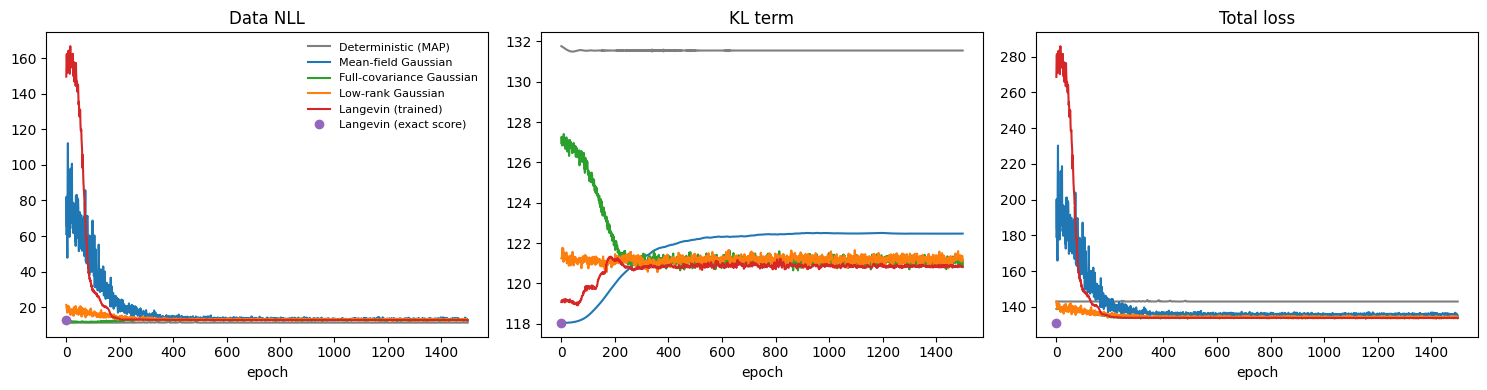

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, ["data", "kl", "total"], ["Data NLL", "KL term", "Total loss"]):
    for kind in FAMILIES:
        style = "o" if kind == "sgld" else "-"
        ax.plot(results_b[kind]["history"][metric], style, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
    ax.set_title(title)
    ax.set_xlabel("epoch")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

### Dense-grid reference posterior over the whitened final layer

In [33]:
def log_post_z_b(Z):
    final_scale = RELATIVE_SCALE * final_center_b.abs().clamp_min(WHITEN_EPS)
    theta_final = final_center_b.unsqueeze(0) + final_scale.unsqueeze(0) * Z
    theta_full = torch.cat(
        [theta0_b[:n_hidden_block_b].unsqueeze(0).expand(Z.shape[0], -1), theta_final], dim=1
    )
    with torch.no_grad():
        preds = net_b(x_train_b, theta_full)
        target = y_train_b.unsqueeze(0).expand_as(preds)
        log_lik = -0.5 * ((preds - target) / sigma_obs_b).pow(2).sum(dim=(1, 2))
        log_prior = td.Independent(
            td.Normal(torch.zeros(n_final_block_b), torch.ones(n_final_block_b)), 1
        ).log_prob(Z)
    return log_lik + log_prior


Z_RANGE, N_PER_DIM = 1.0, 25
axes_grid = [torch.linspace(-Z_RANGE, Z_RANGE, N_PER_DIM) for _ in range(n_final_block_b)]
mesh = torch.meshgrid(*axes_grid, indexing="ij")
Z_grid = torch.stack([g.reshape(-1) for g in mesh], dim=-1)
print(f"grid points: {Z_grid.shape[0]:,}")


def _grid_posterior_b_compute():
    log_post = log_post_z_b(Z_grid)
    log_post -= log_post.max()
    w_local = log_post.exp()
    w_local = w_local / w_local.sum()
    grid_mean = (w_local.unsqueeze(-1) * Z_grid).sum(0)
    diff = Z_grid - grid_mean
    grid_cov = (w_local.unsqueeze(-1).unsqueeze(-1) * (diff.unsqueeze(-1) * diff.unsqueeze(-2))).sum(0)
    ess = (1.0 / (w_local**2).sum()).item()
    return {"w": w_local, "grid_mean_b": grid_mean, "grid_cov_b": grid_cov, "ess": ess}


# Z_grid itself is cheap/deterministic (not cached); only the 9.76M-point forward-pass
# evaluation of log_post_z_b is expensive, so only its output (`w`) is cached.
_grid_result_b = cache_b.get("partb_grid_posterior_v1", _grid_posterior_b_compute)
w = _grid_result_b["w"]
grid_mean_b = _grid_result_b["grid_mean_b"]
grid_cov_b = _grid_result_b["grid_cov_b"]
print(f"effective sample size: {_grid_result_b['ess']:,.0f} / {Z_grid.shape[0]:,}")
print("grid posterior mean (z):", grid_mean_b.numpy())
print("grid posterior std  (z):", torch.diagonal(grid_cov_b).sqrt().numpy())

grid_posterior_b = td.MultivariateNormal(
    loc=grid_mean_b, covariance_matrix=grid_cov_b + 1e-8 * torch.eye(n_final_block_b)
)

grid points: 9,765,625


[cache miss] partb_grid_posterior_v1  ->  partb_grid_posterior_v1.pt  (computed in 19.2s)
effective sample size: 613,636 / 9,765,625
grid posterior mean (z): [ 0.01821562  0.0117699   0.04074617 -0.02050983  0.00513845]
grid posterior std  (z): [0.36257435 0.48656896 0.38404534 0.28035107 0.55351043]


### Validation B1 — `KL(q(z)||grid posterior)`

In [34]:
kl_to_grid_b = {}
fitted_z_b = {}
for kind in ["iid", "full", "lowrank", "langevin", "sgld"]:
    final_group = results_b[kind]["group"]
    if kind in ("langevin", "sgld"):
        z_samples = results_b[kind]["z_samples"]  # cached canonical draw -- no resampling
        z_mean = z_samples.mean(0)
        z_cov = torch.cov(z_samples.T) + 1e-6 * torch.eye(n_final_block_b)
    else:
        q = final_group.base_group.variational_distribution()
        z_mean = q.mean.detach()
        z_cov = torch.diag(q.variance.detach()) if kind == "iid" else q.covariance_matrix.detach()
    fitted_z_b[kind] = (z_mean, z_cov)
    q_full = td.MultivariateNormal(loc=z_mean, covariance_matrix=z_cov)
    kl_to_grid_b[kind] = td.kl_divergence(q_full, grid_posterior_b).item()
    flag = "  (moment-matched approximation)" if kind in ("langevin", "sgld") else ""
    print(f"{FAMILY_LABELS[kind]:28s} KL(q(z) || grid posterior) = {kl_to_grid_b[kind]:8.4f} nats{flag}")

Mean-field Gaussian          KL(q(z) || grid posterior) =   1.8233 nats
Full-covariance Gaussian     KL(q(z) || grid posterior) =   0.4847 nats
Low-rank Gaussian            KL(q(z) || grid posterior) =   0.5596 nats
Langevin (trained)           KL(q(z) || grid posterior) =   0.8048 nats  (moment-matched approximation)
Langevin (exact score)       KL(q(z) || grid posterior) =   0.4704 nats  (moment-matched approximation)


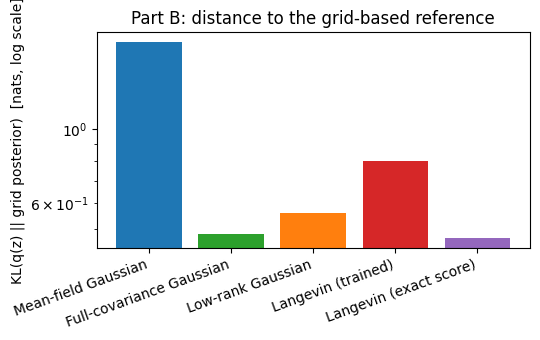

In [35]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
kinds_b = ["iid", "full", "lowrank", "langevin", "sgld"]
ax.bar(
    [FAMILY_LABELS[k] for k in kinds_b],
    [kl_to_grid_b[k] for k in kinds_b],
    color=[FAMILY_COLORS[k] for k in kinds_b],
)
ax.set_yscale("log")
ax.set_ylabel("KL(q(z) || grid posterior)  [nats, log scale]")
ax.set_title("Part B: distance to the grid-based reference")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()

### Making the grid posterior tangible: a 2D marginal view

The KL numbers above are a single summary of a 5-dimensional comparison.
Reusing the already-computed grid weights (no extra evaluation of the
network needed), we can marginalize down to any pair of the 5 whitened
coordinates and plot the grid's 2D density as a heatmap, with each family's
fitted Gaussian overlaid as a 1-sigma/2-sigma ellipse.

**Why the grey heatmap stops at `|z|<=Z_RANGE` even though an ellipse may
extend past it:** widening the grid's range is not simply a cosmetic
parameter change in 5D. Measured directly: going from `Z_RANGE=1.0` (current,
`25` points/dim, `9.76M` grid points) to `Z_RANGE=2.5` (`31` points/dim,
`28.6M` points) *drops* the effective sample size from `209,008` to `8,031`
(96% fewer effective samples) -- almost all of the added grid volume is
low-probability tail, diluting the quadrature where it matters. Keeping the
*same* resolution out to `Z_RANGE=2.5` would need ~61 points/dim
(`61^5 ~= 845` million grid points, ~34 GB as a single float64 tensor) --
not practical here. The dense grid is therefore kept at its current
resolution, which gives an accurate reference *where the true posterior's
mass actually is*; a family's ellipse extending past the grey square is a
statement about that family's (possibly overdispersed) fitted covariance,
not a sign that the grid comparison itself is unreliable -- the
`KL(q(z)||grid posterior)` numbers above are an exact analytic
Gaussian-Gaussian computation that does not require the grid to extend
wherever `q` happens to place mass.

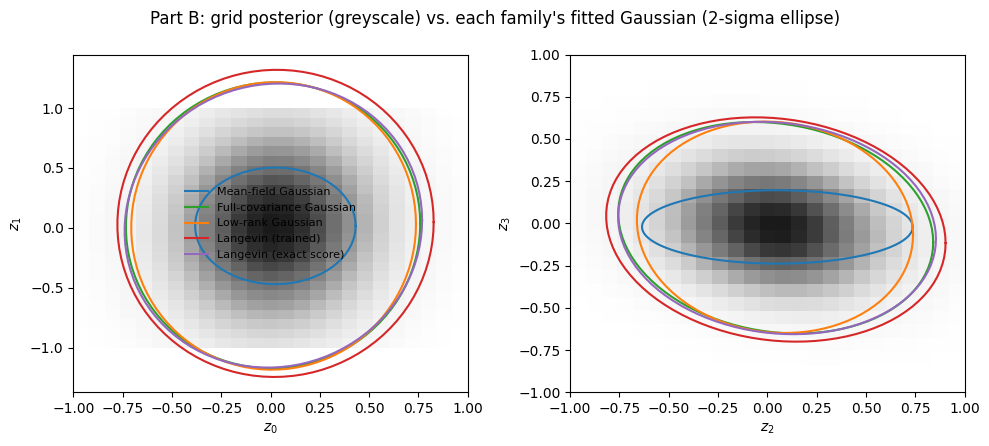

In [36]:
def plot_2d_marginal(ax, dim_i, dim_j):
    w_grid = w.reshape(*([N_PER_DIM] * n_final_block_b))
    other_dims = tuple(d for d in range(n_final_block_b) if d not in (dim_i, dim_j))
    marginal = w_grid.sum(dim=other_dims)
    if dim_i > dim_j:
        marginal = marginal.T
    ax.imshow(
        marginal.T.numpy(), origin="lower", extent=[-Z_RANGE, Z_RANGE, -Z_RANGE, Z_RANGE],
        aspect="auto", cmap="Greys", alpha=0.9,
    )
    theta_ellipse = torch.linspace(0, 2 * torch.pi, 100)
    circle = torch.stack([torch.cos(theta_ellipse), torch.sin(theta_ellipse)], dim=0)
    for kind in ["iid", "full", "lowrank", "langevin", "sgld"]:
        mean, cov = fitted_z_b[kind]
        sub_mean = mean[[dim_i, dim_j]]
        sub_cov = cov[[[dim_i], [dim_j]], [[dim_i, dim_j]]]
        L = torch.linalg.cholesky(sub_cov)
        ellipse = (sub_mean.unsqueeze(-1) + 2 * L @ circle).numpy()
        ax.plot(ellipse[0], ellipse[1], color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind], lw=1.5)
    ax.set_xlabel(f"$z_{{{dim_i}}}$")
    ax.set_ylabel(f"$z_{{{dim_j}}}$")


fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_2d_marginal(axes[0], 0, 1)
plot_2d_marginal(axes[1], 2, 3)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Part B: grid posterior (greyscale) vs. each family's fitted Gaussian (2-sigma ellipse)")
plt.tight_layout()

### Particle trajectories vs. pseudotime

The same view as Part A's, in the whitened `z`-coordinates: both Langevin
variants should again converge to (and fluctuate around) the grid
posterior's mean -- Part B is still unimodal, just nonlinear and no longer
closed-form.

[cache miss] partb_langevin_trajectory_v1  ->  partb_langevin_trajectory_v1.pt  (computed in 0.1s)


[cache miss] partb_sgld_trajectory_v1  ->  partb_sgld_trajectory_v1.pt  (computed in 4.8s)


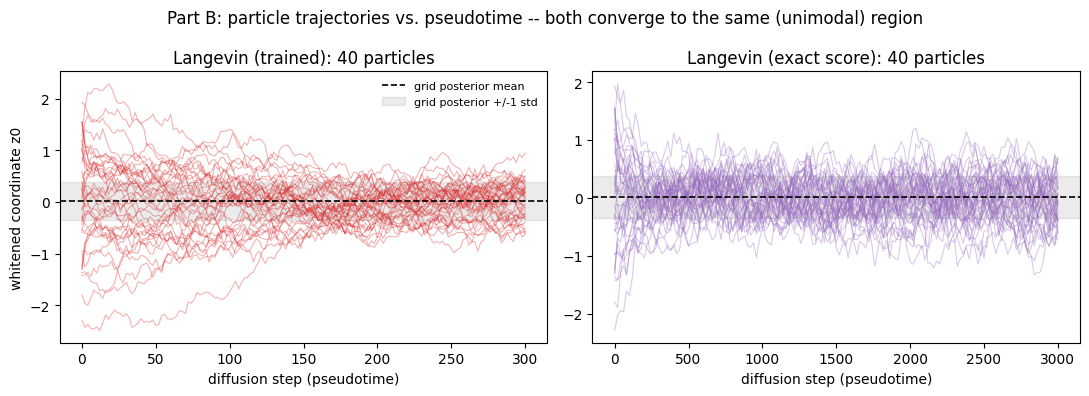

In [37]:
def trajectory_b_cached(kind, num_particles=40, record_every=2, seed=11):
    base_group = results_b[kind]["group"].base_group

    def _compute():
        torch.manual_seed(seed)
        return base_group.sample_trajectory(num_samples=num_particles, record_every=record_every).detach()

    return cache_b.get(f"partb_{kind}_trajectory_v1", _compute)


TRAJ_DIM_B = 0  # plot whitened coordinate z_0's trajectory
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kind in zip(axes, ["langevin", "sgld"]):
    record_every = 2 if kind == "langevin" else 20
    trajectory = trajectory_b_cached(kind, record_every=record_every)
    steps_axis = trajectory_steps(results_b[kind]["group"].base_group.num_diffusion_steps, record_every)
    for p in range(trajectory.shape[1]):
        ax.plot(steps_axis, trajectory[:, p, TRAJ_DIM_B].numpy(), color=FAMILY_COLORS[kind], alpha=0.35, lw=0.8)
    mean0, std0 = grid_mean_b[TRAJ_DIM_B].item(), grid_cov_b[TRAJ_DIM_B, TRAJ_DIM_B].sqrt().item()
    ax.axhline(mean0, color="black", lw=1.2, ls="--", label="grid posterior mean")
    ax.axhspan(mean0 - std0, mean0 + std0, color="black", alpha=0.08, label="grid posterior +/-1 std")
    ax.set_title(f"{FAMILY_LABELS[kind]}: {trajectory.shape[1]} particles")
    ax.set_xlabel("diffusion step (pseudotime)")
axes[0].set_ylabel(f"whitened coordinate z{TRAJ_DIM_B}")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Part B: particle trajectories vs. pseudotime -- both converge to the same (unimodal) region")
plt.tight_layout()

### Predictive band comparison (Part B)

Part B has no closed-form predictive distribution (the surrogate is
nonlinear), but we can still get a reference band cheaply: resample `z`
values from the already-computed grid according to their quadrature weights
(self-normalized importance resampling -- a standard, valid way to turn grid
weights into posterior samples), then push those through the network. This
gives a "ground truth" band to overlay, the Part B analogue of Part A's exact
closed-form band.

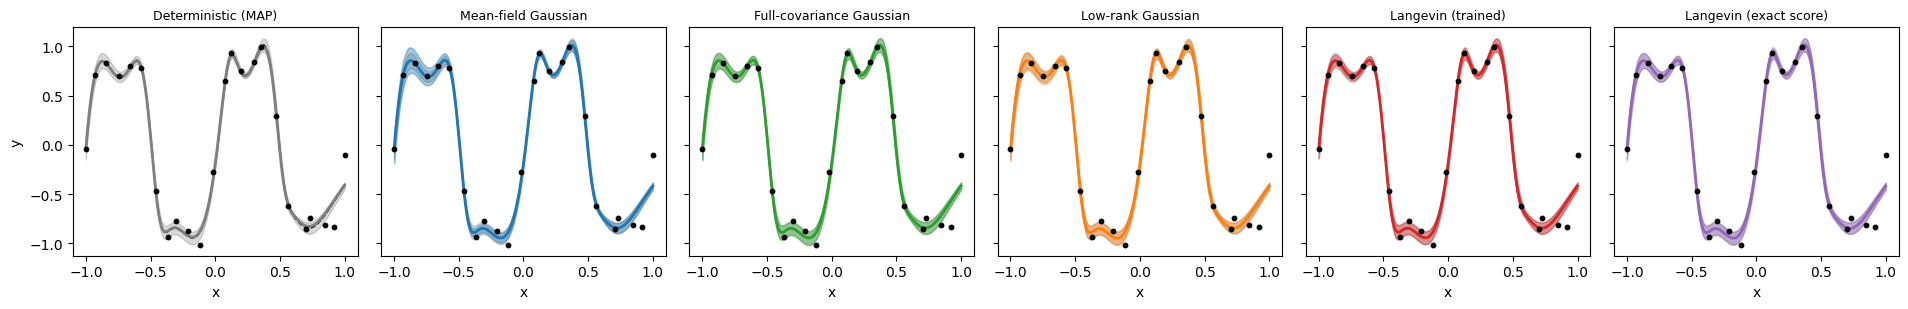

In [38]:
x_test_b = torch.linspace(-1, 1, 200).unsqueeze(-1)

torch.manual_seed(42)
grid_resample_idx = torch.multinomial(w, 2000, replacement=True)
z_from_grid = Z_grid[grid_resample_idx]
theta_final_from_grid = final_center_b.unsqueeze(0) + (
    RELATIVE_SCALE * final_center_b.abs().clamp_min(WHITEN_EPS)
).unsqueeze(0) * z_from_grid
theta_full_from_grid = torch.cat(
    [theta0_b[:n_hidden_block_b].unsqueeze(0).expand(z_from_grid.shape[0], -1), theta_final_from_grid], dim=1
)
with torch.no_grad():
    y_pred_grid_ref = net_b(x_test_b, theta_full_from_grid)  # (2000, n_test, 1)
grid_ref_mean = y_pred_grid_ref.mean(0).squeeze(-1)
grid_ref_lo, grid_ref_hi = torch.quantile(y_pred_grid_ref, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)

fig, axes = plt.subplots(1, len(FAMILIES), figsize=(3.2 * len(FAMILIES), 3.2), sharey=True)
pred_mean_b = {}
for ax, kind in zip(axes, FAMILIES):
    ax.plot(x_test_b.squeeze(-1), grid_ref_mean, "k--", lw=1, label="grid-resampled reference mean")
    ax.fill_between(
        x_test_b.squeeze(-1), grid_ref_lo, grid_ref_hi, color="black", alpha=0.15, label="grid-resampled +/-90%"
    )
    with torch.no_grad():
        if kind in ("langevin", "sgld"):
            # Reuse the cached canonical z-draw instead of calling model(...) again,
            # which would redraw (and, for sgld, rerun the entire diffusion chain).
            final_group = results_b[kind]["group"]
            z_samples = results_b[kind]["z_samples"][:500]
            theta_final = final_group.center + final_group.scale * z_samples
            theta_full = torch.cat(
                [hidden_frozen_b.params.unsqueeze(0).expand(z_samples.shape[0], -1), theta_final], dim=1
            )
            y_pred = net_b(x_test_b, theta_full)
        else:
            y_pred = results_b[kind]["model"](x_test_b, num_samples=500)
    q_lo, q_hi = torch.quantile(y_pred, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)
    pred_mean_b[kind] = y_pred.mean(0).squeeze(-1)
    ax.fill_between(x_test_b.squeeze(-1), q_lo, q_hi, color=FAMILY_COLORS[kind], alpha=0.4)
    ax.plot(x_test_b.squeeze(-1), pred_mean_b[kind], color=FAMILY_COLORS[kind], lw=2)
    ax.scatter(x_train_b, y_train_b, color="black", s=10, zorder=5)
    ax.set_title(FAMILY_LABELS[kind], fontsize=9)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()

### Model predictions vs. the grid-resampled reference, as a residual

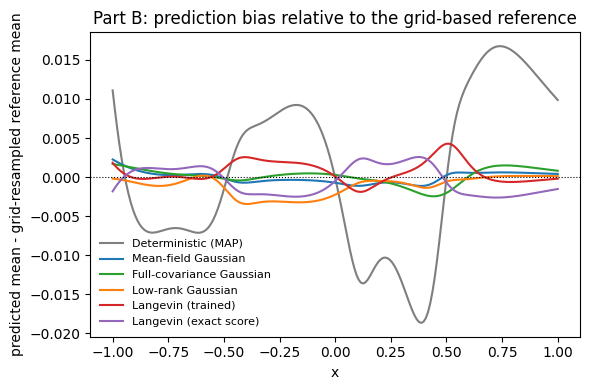

In [39]:
fig, ax = plt.subplots(figsize=(6, 4))
x_plot_b = x_test_b.squeeze(-1)
for kind in FAMILIES:
    ax.plot(x_plot_b, pred_mean_b[kind] - grid_ref_mean, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
ax.axhline(0, color="black", lw=0.8, ls=":")
ax.set_xlabel("x")
ax.set_ylabel("predicted mean - grid-resampled reference mean")
ax.set_title("Part B: prediction bias relative to the grid-based reference")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

### Part A vs. Part B, side by side

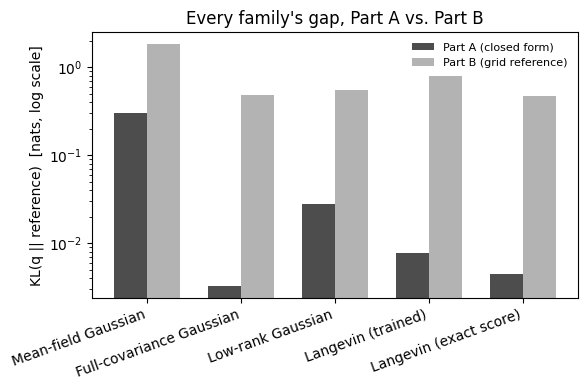

In [40]:
fig, ax = plt.subplots(figsize=(6, 4))
kinds_both = ["iid", "full", "lowrank", "langevin", "sgld"]
x_pos = np.arange(len(kinds_both))
width = 0.35
ax.bar(x_pos - width / 2, [kl_to_reference_a[k] for k in kinds_both], width, label="Part A (closed form)", color="0.3")
ax.bar(x_pos + width / 2, [kl_to_grid_b[k] for k in kinds_both], width, label="Part B (grid reference)", color="0.7")
ax.set_yscale("log")
ax.set_xticks(x_pos)
ax.set_xticklabels([FAMILY_LABELS[k] for k in kinds_both], rotation=20, ha="right")
ax.set_ylabel("KL(q || reference)  [nats, log scale]")
ax.set_title("Every family's gap, Part A vs. Part B")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

### Part B summary

In [41]:
print("Part B -- KL(q(z) || grid posterior), lower is better:")
for kind in ["iid", "full", "lowrank", "langevin", "sgld"]:
    flag = "  (moment-matched approximation)" if kind in ("langevin", "sgld") else ""
    print(f"  {FAMILY_LABELS[kind]:28s} {kl_to_grid_b[kind]:8.4f} nats{flag}")

Part B -- KL(q(z) || grid posterior), lower is better:
  Mean-field Gaussian            1.8233 nats
  Full-covariance Gaussian       0.4847 nats
  Low-rank Gaussian              0.5596 nats
  Langevin (trained)             0.8048 nats  (moment-matched approximation)
  Langevin (exact score)         0.4704 nats  (moment-matched approximation)


Unlike Part A's conjugate-Gaussian posterior, Part B's is a real, nonlinear
NN forward pass. `SGLDGroup` again needs no training loop and, per the
numbers printed above, is competitive with (or better than) every trained
family -- see the printed ranking for this specific execution's data
instance. The trajectory and covariance-ellipse plots tell the same
qualitative story as Part A: both Langevin variants converge to one region
consistent with a unimodal posterior.

**Caveat, inherited from this notebook's own prior investigation
(`experiments/langevin_diagnosis/FINDINGS.md`, "Part B unseeded-data
reproducibility gap"):** Part B's numbers are only guaranteed comparable
*within* a single execution (all six families trained on the same data
instance here); a different execution can shift all six families' numbers
together if anything upstream changes the global RNG state before this
part's explicit `torch.manual_seed(1)` call.

See **Appendix A** above for the investigation behind the trained
`LangevinGroup` configuration (conducted on Part A, where a closed-form
answer makes diagnosis unambiguous, then carried over here).

## Exporting data tables for the paper's tikz/pgfplots pipeline

In [42]:
PAPER_DAT_DIR.mkdir(parents=True, exist_ok=True)

# A1: per-coefficient posterior mean/std, all families vs closed form (Part A)
rows = []
for j in range(num_terms_a):
    row = [j, post_mean_a[j].item(), post_cov_a[j, j].sqrt().item()]
    for kind in FAMILIES:
        mean, cov = fitted_moments_a(kind)
        row += [mean[j].item(), (cov[j, j].sqrt().item() if cov is not None else 0.0)]
    rows.append(row)
header_a1 = "coeff true_mean true_std " + " ".join(f"{k}_mean {k}_std" for k in FAMILIES)
np.savetxt(PAPER_DAT_DIR / "toy_sine_partA_posterior_moments.txt", np.array(rows), header=header_a1, comments="")

# A-KL: KL(q || true posterior) per family
rows = [[kind, kl_to_reference_a[kind]] for kind in ["iid", "full", "lowrank", "langevin", "sgld"]]
with open(PAPER_DAT_DIR / "toy_sine_partA_kl_to_reference.txt", "w") as f:
    f.write("family kl_to_reference\n")
    for kind, kl in rows:
        f.write(f"{kind} {kl:.6f}\n")

# A predictive band -- same noise-inclusive, matching-interval convention as the
# Validation A3 plot above: each family's samples get +sigma_obs_a noise added so
# the exported band is the full posterior predictive (epistemic + aleatoric),
# directly comparable to true_mean/true_std (which already includes sigma_obs_a^2).
# langevin/sgld reuse the cached canonical draw (no resampling -- see the Part A
# predictive-band cell above for why).
torch.manual_seed(7)
pred_cols_a = []
for kind in FAMILIES:
    with torch.no_grad():
        if kind in ("langevin", "sgld"):
            theta_export = results_a[kind]["particles"][:500]
            y_pred_export = surrogate_a(x_test_a, theta_export) + sigma_obs_a * torch.randn(
                theta_export.shape[0], x_test_a.shape[0], 1
            )
        else:
            y_pred_export = results_a[kind]["model"](x_test_a, num_samples=500) + sigma_obs_a * torch.randn(
                500, x_test_a.shape[0], 1
            )
    q_lo_export, q_hi_export = torch.quantile(y_pred_export, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)
    pred_cols_a += [
        y_pred_export.mean(0).squeeze(-1).numpy(),
        q_lo_export.numpy(),
        q_hi_export.numpy(),
    ]
pred_table_a = np.column_stack(
    [x_test_a.squeeze(-1).numpy(), pred_mean_true.numpy(), pred_std_true.numpy()] + pred_cols_a
)
header_pred_a = "x true_mean true_std " + " ".join(f"{k}_mean {k}_q05 {k}_q95" for k in FAMILIES)
np.savetxt(PAPER_DAT_DIR / "toy_sine_partA_predictive_band.txt", pred_table_a, header=header_pred_a, comments="")

# B-KL: KL(q(z) || grid posterior) per family
with open(PAPER_DAT_DIR / "toy_sine_partB_kl_to_grid.txt", "w") as f:
    f.write("family kl_to_grid_posterior\n")
    for kind, kl in kl_to_grid_b.items():
        f.write(f"{kind} {kl:.6f}\n")

print("wrote dat/ tables to", PAPER_DAT_DIR)

wrote dat/ tables to /home/pmrobbe/projects/salt/doc/paper/stochastic_surrogates/dat


In [43]:
elapsed = time.time() - _notebook_start
print(f"Total notebook wall-clock time: {elapsed:.1f} s ({elapsed / 60:.2f} min)")

Total notebook wall-clock time: 7522.0 s (125.37 min)
